<a href="https://colab.research.google.com/github/adhh0715/zepto-dark-store-stock-control/blob/main/Zepto_Dark_Store_Order_Stock_Control.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Zepto Dark Store Order & Stock Control Database
## SQL Developer Colab

**Industry:** Quick Commerce  
**Role:** SQL Developer  
**Runtime:** Google Colab  
**Database:** SQLite  
**Product area:** Dark Store Fulfilment, Inventory and Order Operations

**Main skills:** relational design, SQL analysis, internal API consumption, transaction integrity, workflow automation, and safe database engineering.

Zepto dark-store operations coordinate order capture, item reservation, picking, substitutions, cancellations, delivery and refund events. This notebook creates a controlled internal Dataset and relational database so operational exceptions can be detected and reported through SQL.


## How to Use This Notebook

1. In Google Colab, choose **Runtime -> Run all**.
2. Wait for the **SETUP COMPLETE** message.
3. Begin only after the large **SQL DEVELOPER WORK STARTS HERE** heading.
4. Edit only cells marked **SQL DEVELOPER WORKSPACE**.
5. Every workspace has a validator and is rerunnable. Unanswered workspaces return **Needs Review** rather than a runtime error.
6. Compare your result with the Expected Output block after each activity.


# 1. RUN THIS SETUP ONCE - DO NOT EDIT

Everything required for the internal product is prepared here: environment, deterministic Dataset, controlled internal API, JSON extraction, validation, SQLite, helper functions, and the operational exception engine.


## 1.1 Environment and Project Folder


In [1]:
from __future__ import annotations
import copy, hashlib, json, os, random, re, shutil, sqlite3, subprocess, sys, threading, time
from datetime import datetime, timedelta
from pathlib import Path

import pandas as pd
import requests
from IPython.display import display, SVG

try:
    from graphviz import Digraph
except Exception:
    subprocess.check_call([sys.executable,"-m","pip","install","-q","graphviz"])
    from graphviz import Digraph

RUNTIME_ROOT = Path("/content") if Path("/content").exists() else Path("/mnt/data")
PROJECT_ROOT = RUNTIME_ROOT / "zepto_dark_store_order_stock_control"
RAW_DIR = PROJECT_ROOT / "raw_json"
DB_DIR = PROJECT_ROOT / "database"
for p in [PROJECT_ROOT,RAW_DIR,DB_DIR]: p.mkdir(parents=True,exist_ok=True)
SEED = 20260812
random.seed(SEED)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
print(f"Environment ready | Project folder: {PROJECT_ROOT} | Seed: {SEED}")


Environment ready | Project folder: /content/zepto_dark_store_order_stock_control | Seed: 20260812


## 1.2 Dataset

The Dataset is generated with a fixed seed and controlled dark-store operational anomalies.


In [2]:
def generate_dataset(seed: int = SEED):
    rng = random.Random(seed)
    cities = ["Bengaluru", "Mumbai", "Delhi NCR", "Hyderabad", "Chennai", "Pune"]
    store_names = [
        "Indiranagar", "Koramangala", "Andheri", "Powai", "Saket", "Gurugram Sector 43",
        "Hitech City", "Banjara Hills", "Adyar", "Velachery", "Baner", "Kharadi"
    ]
    stores = []
    for i, name in enumerate(store_names, 1):
        city = cities[(i-1)//2]
        stores.append({
            "store_id": f"DS{i:03d}", "store_name": f"Zepto {name}", "city": city,
            "zone_code": f"Z{((i-1)%6)+1:02d}", "store_status": "ACTIVE",
            "fulfilment_sla_minutes": 18 + ((i * 3) % 10),
            "opened_date": f"202{3 + (i % 3)}-{((i*2)%12)+1:02d}-{((i*5)%27)+1:02d}"
        })

    categories = ["Fruits & Vegetables", "Dairy", "Snacks", "Beverages", "Household", "Personal Care"]
    product_roots = {
        "Fruits & Vegetables": ["Banana", "Apple", "Tomato", "Potato", "Onion", "Orange", "Cucumber", "Spinach", "Mango", "Carrot"],
        "Dairy": ["Milk", "Curd", "Paneer", "Butter", "Cheese", "Yogurt", "Buttermilk", "Cream", "Ghee", "Lassi"],
        "Snacks": ["Potato Chips", "Nachos", "Cookies", "Namkeen", "Popcorn", "Granola Bar", "Crackers", "Peanuts", "Trail Mix", "Khakhra"],
        "Beverages": ["Cola", "Orange Juice", "Coconut Water", "Energy Drink", "Soda", "Iced Tea", "Coffee Can", "Lemonade", "Mineral Water", "Mango Drink"],
        "Household": ["Dishwash Liquid", "Floor Cleaner", "Detergent", "Garbage Bags", "Tissues", "Aluminium Foil", "Sponge", "Toilet Cleaner", "Air Freshener", "Paper Towels"],
        "Personal Care": ["Shampoo", "Soap", "Toothpaste", "Face Wash", "Deodorant", "Hand Wash", "Body Lotion", "Sanitary Pads", "Razor", "Hair Oil"],
    }
    products = []
    pid = 1
    for cat in categories:
        for j, root in enumerate(product_roots[cat], 1):
            products.append({
                "product_id": f"P{pid:04d}", "product_name": f"{root} {250 + ((pid*125)%1000)}g",
                "category": cat, "unit_price": round(25 + ((pid * 37) % 475) + ((pid % 4) * 0.5), 2),
                "product_status": "ACTIVE" if pid % 29 else "PAUSED"
            })
            pid += 1

    inventory = []
    for sidx, store in enumerate(stores, 1):
        for pidx, product in enumerate(products, 1):
            on_hand = 16 + ((sidx * 13 + pidx * 7) % 85)
            reserved = (sidx * pidx) % 8
            if pidx % 19 == 0 and sidx % 3 == 0:
                on_hand = 4 + (sidx % 3)
                reserved = 2
            inventory.append({
                "store_id": store["store_id"], "product_id": product["product_id"],
                "on_hand_qty": on_hand, "reserved_qty": reserved,
                "reorder_level": 10 + ((pidx + sidx) % 12),
                "last_stocked_at": f"2026-07-{1 + ((pidx+sidx*2)%31):02d} {6 + (pidx%12):02d}:00:00"
            })

    product_map = {p["product_id"]: p for p in products}
    orders, order_items, events, deliveries = [], [], [], []
    event_counter = 1
    delivery_counter = 1
    base = datetime(2026, 7, 1, 7, 0, 0)

    for i in range(1, 901):
        store = stores[(i * 5 + 3) % len(stores)]
        ts = base + timedelta(days=(i * 11) % 31, minutes=(i * 37) % (15 * 60))
        # A deterministic mix of lifecycle states.
        if i % 17 == 0:
            order_status = "CANCELLED"
        elif i % 13 == 0:
            order_status = "OUT_FOR_DELIVERY"
        elif i % 11 == 0:
            order_status = "PICKING"
        elif i % 7 == 0:
            order_status = "CONFIRMED"
        else:
            order_status = "DELIVERED"
        payment_status = "PENDING" if i % 23 == 0 else "PAID"
        # Cancelled orders follow the refund-control rule explicitly:
        # pending refunds stay PAID until refund completion; completed refunds are REFUNDED.
        if order_status == "CANCELLED":
            payment_status = "REFUNDED" if i % 34 == 0 else "PAID"
        promised = ts + timedelta(minutes=store["fulfilment_sla_minutes"])
        order_id = f"ORD{i:05d}"
        n_items = 2 + (i % 4)
        total = 0.0
        item_rows = []
        shortage_order = (i % 29 == 0)
        for line in range(1, n_items + 1):
            pidx = (i * 7 + line * 11 + (i % 5)) % len(products)
            product = products[pidx]
            qty = 1 + ((i + line) % 4)
            if shortage_order and line == 1:
                qty = 8
            reserved_qty = qty
            picked_qty = qty
            item_status = "FULFILLED"
            substitute_product_id = None
            if order_status == "CANCELLED":
                picked_qty = 0
                item_status = "CANCELLED"
            elif shortage_order and line == 1:
                reserved_qty = max(0, qty - 3)
                picked_qty = reserved_qty
                item_status = "SHORT"
                if i % 58 == 0:
                    substitute_product_id = products[(pidx + 1) % len(products)]["product_id"]
                    item_status = "SUBSTITUTED"
                    picked_qty = qty
                    reserved_qty = qty
            elif order_status in ("CONFIRMED", "PICKING") and line == n_items:
                picked_qty = max(0, qty - (1 if i % 4 == 0 else 0))
                item_status = "RESERVED" if order_status == "CONFIRMED" else "PICKING"
            amount = qty * product["unit_price"]
            total += amount
            row = {
                "order_id": order_id, "line_no": line, "product_id": product["product_id"],
                "requested_qty": qty, "reserved_qty": reserved_qty, "picked_qty": picked_qty,
                "unit_price": product["unit_price"], "item_status": item_status,
                "substitute_product_id": substitute_product_id
            }
            order_items.append(row)
            item_rows.append(row)

        orders.append({
            "order_id": order_id, "store_id": store["store_id"],
            "customer_ref": f"CUST{100000 + ((i*7919)%700000):06d}",
            "order_timestamp": ts.strftime("%Y-%m-%d %H:%M:%S"),
            "order_status": order_status, "payment_status": payment_status,
            "total_amount": round(total, 2),
            "promised_fulfilment_at": promised.strftime("%Y-%m-%d %H:%M:%S")
        })

        # Core operational events.
        events.append({"event_id": f"EVT{event_counter:06d}", "order_id": order_id, "line_no": None, "product_id": None,
                       "event_type": "ORDER_CREATED", "quantity": None, "event_timestamp": ts.strftime("%Y-%m-%d %H:%M:%S"),
                       "event_status": "COMPLETED", "amount_value": None, "reference_id": f"OC-{order_id}"})
        event_counter += 1
        for item in item_rows:
            reserve_time = ts + timedelta(minutes=2 + item["line_no"])
            if not (shortage_order and item["line_no"] == 1 and i % 87 == 0):
                events.append({"event_id": f"EVT{event_counter:06d}", "order_id": order_id, "line_no": item["line_no"], "product_id": item["product_id"],
                               "event_type": "STOCK_RESERVED", "quantity": item["reserved_qty"], "event_timestamp": reserve_time.strftime("%Y-%m-%d %H:%M:%S"),
                               "event_status": "COMPLETED" if item["reserved_qty"] else "FAILED", "amount_value": None, "reference_id": f"RSV-{order_id}-{item['line_no']}"})
                event_counter += 1
            if item["substitute_product_id"]:
                events.append({"event_id": f"EVT{event_counter:06d}", "order_id": order_id, "line_no": item["line_no"], "product_id": item["substitute_product_id"],
                               "event_type": "SUBSTITUTED", "quantity": item["requested_qty"], "event_timestamp": (reserve_time+timedelta(minutes=2)).strftime("%Y-%m-%d %H:%M:%S"),
                               "event_status": "COMPLETED", "amount_value": None, "reference_id": f"SUB-{order_id}-{item['line_no']}"})
                event_counter += 1

        if order_status == "CANCELLED":
            cancel_time = ts + timedelta(minutes=8 + (i % 20))
            events.append({"event_id": f"EVT{event_counter:06d}", "order_id": order_id, "line_no": None, "product_id": None,
                           "event_type": "CANCELLED", "quantity": None, "event_timestamp": cancel_time.strftime("%Y-%m-%d %H:%M:%S"),
                           "event_status": "COMPLETED", "amount_value": None, "reference_id": f"CAN-{order_id}"})
            event_counter += 1
            refund_type = "REFUNDED" if i % 34 == 0 else "REFUND_PENDING"
            events.append({"event_id": f"EVT{event_counter:06d}", "order_id": order_id, "line_no": None, "product_id": None,
                           "event_type": refund_type, "quantity": None, "event_timestamp": (cancel_time+timedelta(minutes=10)).strftime("%Y-%m-%d %H:%M:%S"),
                           "event_status": "COMPLETED" if refund_type == "REFUNDED" else "PENDING", "amount_value": round(total, 2),
                           "reference_id": f"RF-{order_id}"})
            event_counter += 1
        elif order_status in ("PICKING", "OUT_FOR_DELIVERY", "DELIVERED"):
            pick_start = ts + timedelta(minutes=5 + (i % 6))
            pick_duration = 18 if i % 37 == 0 else (5 + (i % 8))
            events.append({"event_id": f"EVT{event_counter:06d}", "order_id": order_id, "line_no": None, "product_id": None,
                           "event_type": "PICK_STARTED", "quantity": None, "event_timestamp": pick_start.strftime("%Y-%m-%d %H:%M:%S"),
                           "event_status": "COMPLETED", "amount_value": None, "reference_id": f"PKS-{order_id}"})
            event_counter += 1
            if not (order_status == "PICKING" and i % 22 == 0):
                pick_complete = pick_start + timedelta(minutes=pick_duration)
                events.append({"event_id": f"EVT{event_counter:06d}", "order_id": order_id, "line_no": None, "product_id": None,
                               "event_type": "PICK_COMPLETED", "quantity": None, "event_timestamp": pick_complete.strftime("%Y-%m-%d %H:%M:%S"),
                               "event_status": "COMPLETED", "amount_value": None, "reference_id": f"PKC-{order_id}"})
                event_counter += 1

        if order_status in ("OUT_FOR_DELIVERY", "DELIVERED") and not (order_status == "OUT_FOR_DELIVERY" and i % 39 == 0):
            dispatch = ts + timedelta(minutes=14 + (i % 8))
            promised_delivery = ts + timedelta(minutes=45)
            late = (i % 31 == 0)
            delivered_at = None
            delivery_status = "OUT_FOR_DELIVERY"
            if order_status == "DELIVERED":
                delivered_at = dispatch + timedelta(minutes=(28 if late else (12 + i % 12)))
                delivery_status = "DELIVERED"
            ext_ref = f"DLVREF-{i:05d}"
            if i % 211 == 0:
                ext_ref = "DLVREF-DUPLICATE-001"
            elif i % 223 == 0:
                ext_ref = "DLVREF-DUPLICATE-001"
            deliveries.append({
                "delivery_id": f"DLV{delivery_counter:05d}", "order_id": order_id, "store_id": store["store_id"],
                "partner_name": ["Zepto Fleet", "Shadowfax", "Loadshare"][i % 3],
                "external_delivery_ref": ext_ref,
                "promised_at": promised_delivery.strftime("%Y-%m-%d %H:%M:%S"),
                "dispatched_at": dispatch.strftime("%Y-%m-%d %H:%M:%S"),
                "delivered_at": delivered_at.strftime("%Y-%m-%d %H:%M:%S") if delivered_at else None,
                "delivery_status": delivery_status
            })
            delivery_counter += 1

    return {
        "dark_stores": pd.DataFrame(stores),
        "products": pd.DataFrame(products),
        "inventory_positions": pd.DataFrame(inventory),
        "orders": pd.DataFrame(orders),
        "order_items": pd.DataFrame(order_items),
        "fulfilment_events": pd.DataFrame(events),
        "deliveries": pd.DataFrame(deliveries),
    }


dataset_frames = generate_dataset(SEED)
for _name,_df in dataset_frames.items():
    print(f'{_name}: {len(_df):,} rows')


dark_stores: 12 rows
products: 60 rows
inventory_positions: 720 rows
orders: 900 rows
order_items: 3,150 rows
fulfilment_events: 5,618 rows
deliveries: 654 rows


In [3]:
# Compatibility repair for the supplied API setup; original setup cells are unchanged.
# Numeric NaN survives DataFrame.where(..., None) on numeric dtypes.
# Cast to object first so missing optional event fields serialize as JSON null.
# No records, business values, validation rules or expected outputs are changed.
dataset_frames = {
    name: frame.astype(object).where(pd.notna(frame), None)
    for name, frame in dataset_frames.items()
}
for name, frame in dataset_frames.items():
    json.dumps(frame.to_dict('records'), allow_nan=False, default=str)
print('JSON compatibility verified: nullable numeric fields serialize as null.')

JSON compatibility verified: nullable numeric fields serialize as null.


## 1.3 Temporary Internal API


In [4]:
# Shut down an earlier server if this setup is re-run in the same runtime.
if "api_server" in globals():
    try:
        api_server.shutdown(); api_server.server_close()
    except Exception:
        pass

from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from urllib.parse import urlparse, parse_qs

api_resource_records = {name: df.where(pd.notna(df), None).to_dict("records") for name, df in dataset_frames.items()}
api_orders_master = {r["order_id"]: dict(r) for r in api_resource_records["orders"]}
api_orders = copy.deepcopy(api_orders_master)

PRACTICE_ORDERS = {
    "ORD-API-PUT": {"order_id":"ORD-API-PUT","store_id":"DS001","customer_ref":"CUST900001","order_timestamp":"2026-07-31 19:00:00","order_status":"CONFIRMED","payment_status":"PAID","total_amount":499.00,"promised_fulfilment_at":"2026-07-31 19:22:00"},
    "ORD-API-PATCH": {"order_id":"ORD-API-PATCH","store_id":"DS002","customer_ref":"CUST900002","order_timestamp":"2026-07-31 19:05:00","order_status":"CONFIRMED","payment_status":"PAID","total_amount":325.50,"promised_fulfilment_at":"2026-07-31 19:28:00"},
    "ORD-API-DELETE": {"order_id":"ORD-API-DELETE","store_id":"DS003","customer_ref":"CUST900003","order_timestamp":"2026-07-31 19:10:00","order_status":"CONFIRMED","payment_status":"PAID","total_amount":189.00,"promised_fulfilment_at":"2026-07-31 19:35:00"}
}

def reset_practice_order(order_id):
    api_orders[order_id] = copy.deepcopy(PRACTICE_ORDERS[order_id])

def reset_post_order(order_id="ORD-API-POST"):
    api_orders.pop(order_id, None)

class InternalAPIHandler(BaseHTTPRequestHandler):
    def log_message(self, fmt, *args):
        return
    def _send(self, status, payload):
        raw = json.dumps(payload, default=str).encode("utf-8")
        self.send_response(status)
        self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(raw)))
        self.end_headers(); self.wfile.write(raw)
    def _body(self):
        n = int(self.headers.get("Content-Length", "0") or 0)
        if not n: return {}
        try: return json.loads(self.rfile.read(n).decode("utf-8"))
        except Exception: return None
    def do_GET(self):
        parsed = urlparse(self.path); path = parsed.path.strip("/"); qs=parse_qs(parsed.query)
        parts = path.split("/") if path else []
        if not parts: return self._send(200,{"service":"Zepto internal order operations API","status":"ready"})
        resource = parts[0]
        if resource == "orders":
            if len(parts)==2:
                rec=api_orders.get(parts[1]); return self._send(200,rec) if rec else self._send(404,{"error":"order not found"})
            rows=list(api_orders.values())
            for key in ["order_status","payment_status","store_id"]:
                if key in qs: rows=[r for r in rows if str(r.get(key))==qs[key][0]]
            rows=sorted(rows,key=lambda r:r["order_id"])
            limit=int(qs.get("limit",[len(rows)])[0]); return self._send(200,rows[:limit])
        if resource in api_resource_records:
            rows=api_resource_records[resource]
            limit=int(qs.get("limit",[len(rows)])[0]); return self._send(200,rows[:limit])
        return self._send(404,{"error":"resource not found"})
    def do_POST(self):
        parsed=urlparse(self.path); resource=parsed.path.strip("/")
        if resource!="orders": return self._send(404,{"error":"resource not found"})
        body=self._body()
        if not isinstance(body,dict): return self._send(400,{"error":"invalid JSON"})
        oid=body.get("order_id")
        required={"order_id","store_id","customer_ref","order_timestamp","order_status","payment_status","total_amount","promised_fulfilment_at"}
        if not oid or not required.issubset(body): return self._send(400,{"error":"missing fields"})
        if oid in api_orders: return self._send(409,{"error":"order exists"})
        api_orders[oid]=dict(body); return self._send(201,api_orders[oid])
    def do_PUT(self):
        parts=urlparse(self.path).path.strip("/").split("/")
        if len(parts)!=2 or parts[0]!="orders": return self._send(404,{"error":"resource not found"})
        oid=parts[1]
        if oid not in api_orders: return self._send(404,{"error":"order not found"})
        body=self._body(); required={"store_id","customer_ref","order_timestamp","order_status","payment_status","total_amount","promised_fulfilment_at"}
        if not isinstance(body,dict) or not required.issubset(body): return self._send(400,{"error":"complete replacement required"})
        replacement={"order_id":oid, **{k:body[k] for k in required}}
        api_orders[oid]=replacement; return self._send(200,replacement)
    def do_PATCH(self):
        parts=urlparse(self.path).path.strip("/").split("/")
        if len(parts)!=2 or parts[0]!="orders": return self._send(404,{"error":"resource not found"})
        oid=parts[1]
        if oid not in api_orders: return self._send(404,{"error":"order not found"})
        body=self._body()
        if not isinstance(body,dict): return self._send(400,{"error":"invalid JSON"})
        api_orders[oid].update(body); return self._send(200,api_orders[oid])
    def do_DELETE(self):
        parts=urlparse(self.path).path.strip("/").split("/")
        if len(parts)!=2 or parts[0]!="orders": return self._send(404,{"error":"resource not found"})
        oid=parts[1]
        if oid not in api_orders: return self._send(404,{"error":"order not found"})
        deleted=api_orders.pop(oid); return self._send(200,{"deleted":True,"order_id":oid,"record":deleted})

api_server = ThreadingHTTPServer(("127.0.0.1",0), InternalAPIHandler)
api_port = api_server.server_address[1]
api_thread = threading.Thread(target=api_server.serve_forever,daemon=True); api_thread.start()
API_BASE_URL=f"http://127.0.0.1:{api_port}"
print(f"Temporary internal API ready: {API_BASE_URL}")


Temporary internal API ready: http://127.0.0.1:41833


In [5]:
api_documentation = pd.DataFrame([
["GET","/dark_stores","Read dark-store master records","200"],
["GET","/products","Read product master records","200"],
["GET","/inventory_positions","Read stock positions","200"],
["GET","/orders","Read orders; supports filters and limit","200"],
["GET","/orders/{id}","Read one order","200 / 404"],
["POST","/orders","Create one practice order","201 / 400 / 409"],
["PUT","/orders/{id}","Completely replace a practice order","200 / 400 / 404"],
["PATCH","/orders/{id}","Update selected practice-order fields","200 / 404"],
["DELETE","/orders/{id}","Delete one practice order","200 / 404"],
["GET","/order_items","Read order item lines","200"],
["GET","/fulfilment_events","Read reservation, picking, substitution, cancellation and refund events","200"],
["GET","/deliveries","Read delivery records","200"]],
columns=["Method","Endpoint","Purpose","Expected status"])
display(api_documentation)


,Method,Endpoint,Purpose,Expected status
0,GET,/dark_stores,Read dark-store master records,200
1,GET,/products,Read product master records,200
2,GET,/inventory_positions,Read stock positions,200
3,GET,/orders,Read orders; supports filters and limit,200
4,GET,/orders/{id},Read one order,200 / 404
5,POST,/orders,Create one practice order,201 / 400 / 409
6,PUT,/orders/{id},Completely replace a practice order,200 / 400 / 404
7,PATCH,/orders/{id},Update selected practice-order fields,200 / 404
8,DELETE,/orders/{id},Delete one practice order,200 / 404
9,GET,/order_items,Read order item lines,200


## 1.4 API Extraction and Dataset Validation


In [6]:
RESOURCE_ENDPOINTS = ["dark_stores","products","inventory_positions","orders","order_items","fulfilment_events","deliveries"]

def fetch_resource(resource):
    response=requests.get(f"{API_BASE_URL}/{resource}",timeout=10)
    response.raise_for_status()
    records=response.json()
    raw_path=RAW_DIR/f"{resource}.json"
    raw_path.write_text(json.dumps(records,indent=2,default=str),encoding="utf-8")
    return records,response.status_code,raw_path

ingestion_runs=[]
extracted_records={}
for idx,resource in enumerate(RESOURCE_ENDPOINTS,1):
    records,status,raw_path=fetch_resource(resource)
    extracted_records[resource]=records
    ingestion_runs.append([f"ING{idx:03d}",f"/{resource}","2026-08-01 05:45:00",len(records),len(records),"SUCCESS",None])
    print(f"{resource}: HTTP {status} | {len(records):,} rows | raw JSON saved")


dark_stores: HTTP 200 | 12 rows | raw JSON saved
products: HTTP 200 | 60 rows | raw JSON saved
inventory_positions: HTTP 200 | 720 rows | raw JSON saved
orders: HTTP 200 | 900 rows | raw JSON saved
order_items: HTTP 200 | 3,150 rows | raw JSON saved
fulfilment_events: HTTP 200 | 5,618 rows | raw JSON saved
deliveries: HTTP 200 | 654 rows | raw JSON saved


In [7]:
DATA_CONTRACTS = {
"dark_stores":["store_id","store_name","city","zone_code","store_status","fulfilment_sla_minutes","opened_date"],
"products":["product_id","product_name","category","unit_price","product_status"],
"inventory_positions":["store_id","product_id","on_hand_qty","reserved_qty","reorder_level","last_stocked_at"],
"orders":["order_id","store_id","customer_ref","order_timestamp","order_status","payment_status","total_amount","promised_fulfilment_at"],
"order_items":["order_id","line_no","product_id","requested_qty","reserved_qty","picked_qty","unit_price","item_status","substitute_product_id"],
"fulfilment_events":["event_id","order_id","line_no","product_id","event_type","quantity","event_timestamp","event_status","amount_value","reference_id"],
"deliveries":["delivery_id","order_id","store_id","partner_name","external_delivery_ref","promised_at","dispatched_at","delivered_at","delivery_status"]}
PRIMARY_KEYS={"dark_stores":["store_id"],"products":["product_id"],"inventory_positions":["store_id","product_id"],"orders":["order_id"],"order_items":["order_id","line_no"],"fulfilment_events":["event_id"],"deliveries":["delivery_id"]}
processed_data={}
quality_rows=[]
for resource,records in extracted_records.items():
    df=pd.DataFrame(records)
    missing=[c for c in DATA_CONTRACTS[resource] if c not in df.columns]
    null_keys=int(df[PRIMARY_KEYS[resource]].isna().any(axis=1).sum()) if not missing else -1
    dup_keys=int(df.duplicated(PRIMARY_KEYS[resource]).sum()) if not missing else -1
    passed=(not missing and null_keys==0 and dup_keys==0)
    quality_rows.append([resource,len(df),", ".join(missing) or "None",null_keys,dup_keys,"Passed" if passed else "Needs Review"])
    processed_data[resource]=df[DATA_CONTRACTS[resource]].copy()
quality_summary=pd.DataFrame(quality_rows,columns=["resource","rows","missing_columns","null_key_rows","duplicate_keys","status"])
display(quality_summary)
print("Dataset contracts validated." if (quality_summary.status=="Passed").all() else "Dataset validation needs review.")


,resource,rows,missing_columns,null_key_rows,duplicate_keys,status
0,dark_stores,12,None,0,0,Passed
1,products,60,None,0,0,Passed
2,inventory_positions,720,None,0,0,Passed
3,orders,900,None,0,0,Passed
4,order_items,3150,None,0,0,Passed
5,fulfilment_events,5618,None,0,0,Passed
6,deliveries,654,None,0,0,Passed


Dataset contracts validated.


## 1.5 SQLite Database Creation


In [8]:
def create_sqlite_database(db_path: str | Path, data: dict[str, pd.DataFrame]):
    db_path = Path(db_path)
    if db_path.exists():
        db_path.unlink()
    conn = sqlite3.connect(db_path)
    conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript(r'''
    CREATE TABLE dark_stores (
        store_id TEXT PRIMARY KEY,
        store_name TEXT NOT NULL,
        city TEXT NOT NULL,
        zone_code TEXT NOT NULL,
        store_status TEXT NOT NULL CHECK(store_status IN ('ACTIVE','PAUSED','CLOSED')),
        fulfilment_sla_minutes INTEGER NOT NULL CHECK(fulfilment_sla_minutes BETWEEN 10 AND 60),
        opened_date TEXT NOT NULL
    );
    CREATE TABLE products (
        product_id TEXT PRIMARY KEY,
        product_name TEXT NOT NULL,
        category TEXT NOT NULL,
        unit_price REAL NOT NULL CHECK(unit_price > 0),
        product_status TEXT NOT NULL CHECK(product_status IN ('ACTIVE','PAUSED','DISCONTINUED'))
    );
    CREATE TABLE inventory_positions (
        store_id TEXT NOT NULL,
        product_id TEXT NOT NULL,
        on_hand_qty INTEGER NOT NULL CHECK(on_hand_qty >= 0),
        reserved_qty INTEGER NOT NULL CHECK(reserved_qty >= 0),
        reorder_level INTEGER NOT NULL CHECK(reorder_level >= 0),
        last_stocked_at TEXT NOT NULL,
        PRIMARY KEY (store_id, product_id),
        FOREIGN KEY (store_id) REFERENCES dark_stores(store_id),
        FOREIGN KEY (product_id) REFERENCES products(product_id),
        CHECK(reserved_qty <= on_hand_qty)
    );
    CREATE TABLE orders (
        order_id TEXT PRIMARY KEY,
        store_id TEXT NOT NULL,
        customer_ref TEXT NOT NULL,
        order_timestamp TEXT NOT NULL,
        order_status TEXT NOT NULL CHECK(order_status IN ('CONFIRMED','PICKING','OUT_FOR_DELIVERY','DELIVERED','CANCELLED')),
        payment_status TEXT NOT NULL CHECK(payment_status IN ('PAID','PENDING','REFUNDED')),
        total_amount REAL NOT NULL CHECK(total_amount >= 0),
        promised_fulfilment_at TEXT NOT NULL,
        FOREIGN KEY (store_id) REFERENCES dark_stores(store_id)
    );
    CREATE TABLE order_items (
        order_id TEXT NOT NULL,
        line_no INTEGER NOT NULL CHECK(line_no > 0),
        product_id TEXT NOT NULL,
        requested_qty INTEGER NOT NULL CHECK(requested_qty > 0),
        reserved_qty INTEGER NOT NULL CHECK(reserved_qty >= 0),
        picked_qty INTEGER NOT NULL CHECK(picked_qty >= 0),
        unit_price REAL NOT NULL CHECK(unit_price > 0),
        item_status TEXT NOT NULL CHECK(item_status IN ('FULFILLED','RESERVED','PICKING','SHORT','SUBSTITUTED','CANCELLED')),
        substitute_product_id TEXT,
        PRIMARY KEY (order_id, line_no),
        FOREIGN KEY (order_id) REFERENCES orders(order_id),
        FOREIGN KEY (product_id) REFERENCES products(product_id),
        FOREIGN KEY (substitute_product_id) REFERENCES products(product_id)
    );
    CREATE TABLE fulfilment_events (
        event_id TEXT PRIMARY KEY,
        order_id TEXT NOT NULL,
        line_no INTEGER,
        product_id TEXT,
        event_type TEXT NOT NULL CHECK(event_type IN ('ORDER_CREATED','STOCK_RESERVED','PICK_STARTED','PICK_COMPLETED','SUBSTITUTED','CANCELLED','REFUND_PENDING','REFUNDED')),
        quantity INTEGER CHECK(quantity IS NULL OR quantity >= 0),
        event_timestamp TEXT NOT NULL,
        event_status TEXT NOT NULL CHECK(event_status IN ('COMPLETED','PENDING','FAILED')),
        amount_value REAL CHECK(amount_value IS NULL OR amount_value >= 0),
        reference_id TEXT,
        FOREIGN KEY (order_id) REFERENCES orders(order_id),
        FOREIGN KEY (product_id) REFERENCES products(product_id),
        FOREIGN KEY (order_id, line_no) REFERENCES order_items(order_id, line_no)
    );
    CREATE TABLE deliveries (
        delivery_id TEXT PRIMARY KEY,
        order_id TEXT NOT NULL UNIQUE,
        store_id TEXT NOT NULL,
        partner_name TEXT NOT NULL,
        external_delivery_ref TEXT NOT NULL,
        promised_at TEXT NOT NULL,
        dispatched_at TEXT NOT NULL,
        delivered_at TEXT,
        delivery_status TEXT NOT NULL CHECK(delivery_status IN ('OUT_FOR_DELIVERY','DELIVERED','FAILED')),
        FOREIGN KEY (order_id) REFERENCES orders(order_id),
        FOREIGN KEY (store_id) REFERENCES dark_stores(store_id)
    );
    CREATE TABLE inventory_movements (
        movement_id TEXT PRIMARY KEY,
        store_id TEXT NOT NULL,
        product_id TEXT NOT NULL,
        order_id TEXT,
        movement_type TEXT NOT NULL CHECK(movement_type IN ('RESERVATION','RELEASE','PICK','SUBSTITUTION','ADJUSTMENT')),
        quantity_delta INTEGER NOT NULL CHECK(quantity_delta <> 0),
        movement_timestamp TEXT NOT NULL,
        reason TEXT NOT NULL,
        FOREIGN KEY (store_id) REFERENCES dark_stores(store_id),
        FOREIGN KEY (product_id) REFERENCES products(product_id),
        FOREIGN KEY (order_id) REFERENCES orders(order_id)
    );
    CREATE TABLE operational_exceptions (
        exception_id TEXT PRIMARY KEY,
        store_id TEXT NOT NULL,
        order_id TEXT,
        product_id TEXT,
        exception_type TEXT NOT NULL,
        severity TEXT NOT NULL CHECK(severity IN ('LOW','MEDIUM','HIGH','CRITICAL')),
        expected_value REAL,
        actual_value REAL,
        status TEXT NOT NULL CHECK(status IN ('OPEN','RESOLVED')),
        detected_at TEXT NOT NULL,
        detail TEXT NOT NULL,
        FOREIGN KEY (store_id) REFERENCES dark_stores(store_id),
        FOREIGN KEY (order_id) REFERENCES orders(order_id),
        FOREIGN KEY (product_id) REFERENCES products(product_id)
    );
    CREATE TABLE api_ingestion_runs (
        run_id TEXT PRIMARY KEY,
        endpoint TEXT NOT NULL,
        extracted_at TEXT NOT NULL,
        rows_received INTEGER NOT NULL CHECK(rows_received >= 0),
        rows_loaded INTEGER NOT NULL CHECK(rows_loaded >= 0),
        status TEXT NOT NULL CHECK(status IN ('SUCCESS','FAILED')),
        error_message TEXT
    );
    CREATE INDEX idx_orders_store_time ON orders(store_id, order_timestamp);
    CREATE INDEX idx_orders_status ON orders(order_status, payment_status);
    CREATE INDEX idx_items_product_status ON order_items(product_id, item_status);
    CREATE INDEX idx_events_order_type ON fulfilment_events(order_id, event_type, event_timestamp);
    CREATE INDEX idx_delivery_status_time ON deliveries(delivery_status, promised_at);
    CREATE INDEX idx_exception_status_type ON operational_exceptions(status, exception_type, severity);
    CREATE INDEX idx_movements_store_product ON inventory_movements(store_id, product_id, movement_timestamp);
    ''')

    order = ["dark_stores","products","inventory_positions","orders","order_items","fulfilment_events","deliveries"]
    for table in order:
        df = data[table]
        cols = list(df.columns)
        placeholders = ','.join(['?']*len(cols))
        conn.executemany(f"INSERT INTO {table} ({','.join(cols)}) VALUES ({placeholders})", df.where(pd.notna(df), None).itertuples(index=False, name=None))
    conn.commit()
    return conn


DB_PATH = DB_DIR / "zepto_dark_store_control.db"
conn = create_sqlite_database(DB_PATH, processed_data)
for _run in ingestion_runs:
    conn.execute("INSERT INTO api_ingestion_runs VALUES (?,?,?,?,?,?,?)", tuple(_run))
conn.commit()
fk_on = conn.execute("PRAGMA foreign_keys").fetchone()[0]
index_count = conn.execute("SELECT COUNT(*) FROM sqlite_master WHERE type='index' AND name NOT LIKE 'sqlite_%'").fetchone()[0]
print(f"SQLite database ready: {DB_PATH}")
print(f"Foreign keys enabled: {bool(fk_on)} | Practical indexes: {index_count}")


SQLite database ready: /content/zepto_dark_store_order_stock_control/database/zepto_dark_store_control.db
Foreign keys enabled: True | Practical indexes: 7


## 1.6 SQL Developer Validation and Visualization Helpers


In [9]:
# ============================================================
# PREBUILT HELPERS - DO NOT EDIT
# ============================================================
ACTIVITY_IDS = ["ER-1"] + [f"API-Q{i}" for i in range(1,6)] + [f"Q{i}" for i in range(1,14)] + ["T1","T2","AUTO-FLOW","AUTO-REPORT","AUTO-CRON","ENG-GIT","ENG-CHANGE"]
activity_status = {aid:"Needs Review" for aid in ACTIVITY_IDS}
EXPECTED_SQL_META = json.loads(r'''{"Q1": {"columns": ["order_id", "store_name", "city", "total_amount", "order_timestamp"], "row_count": 10, "first_row": {"order_id": "ORD00783", "store_name": "Zepto Hitech City", "city": "Hyderabad", "total_amount": 6477.0, "order_timestamp": "2026-07-27 09:51:00"}, "hash": "676e05912434511a75cb8379bf938d5c13279ca3cd9e66fd5a5f087ed24a1328"}, "Q2": {"columns": ["store_id", "store_name", "delivered_orders", "delivered_value"], "row_count": 12, "first_row": {"store_id": "DS003", "store_name": "Zepto Andheri", "delivered_orders": 50, "delivered_value": 175842.5}, "hash": "f87992142ea8c8f663a578d7ba13702252d049ea846ff2c29d5a0c02c03cd7eb"}, "Q3": {"columns": ["order_id", "store_name", "requested_qty", "reserved_qty", "picked_qty", "fulfilment_state"], "row_count": 20, "first_row": {"order_id": "ORD00028", "store_name": "Zepto Kharadi", "requested_qty": 5, "reserved_qty": 5, "picked_qty": 4, "fulfilment_state": "PARTIAL_PICK"}, "hash": "01a3bfa495111689a4a0fc4489dee96e825d61f33efb1247adbbf5f08077bd1d"}, "Q4": {"columns": ["order_id", "store_name", "order_status", "order_timestamp"], "row_count": 22, "first_row": {"order_id": "ORD00234", "store_name": "Zepto Velachery", "order_status": "OUT_FOR_DELIVERY", "order_timestamp": "2026-07-02 16:18:00"}, "hash": "43048b03df3d1a80e8e7df2caa6575b8689ab7f36243fc864b3811c45f32222f"}, "Q5": {"columns": ["store_id"], "row_count": 6, "first_row": {"store_id": "DS001"}, "hash": "9ade2a7c9be62d58042b388cfacfa260c73176585cfe2fec250587fd71a0b9f2"}, "Q6": {"columns": ["store_id", "store_label", "zone_code", "operating_days", "open_exceptions", "risk_band"], "row_count": 12, "first_row": {"store_id": "DS007", "store_label": "ZEPTO HITECH CITY", "zone_code": "Z01", "operating_days": 875, "open_exceptions": 24, "risk_band": "HIGH"}, "hash": "8c0cfa67f3061c48a7ae1da690aa492fb94bf8528a437b7fc86f716ce62758e9"}, "Q7": {"columns": ["store_id", "store_name", "delivered_value"], "row_count": 4, "first_row": {"store_id": "DS003", "store_name": "Zepto Andheri", "delivered_value": 175842.5}, "hash": "b4b3ae93c0308394f4d775a6cd0d5de5d73e87cafd936be5ebd4978c782f3553"}, "Q8": {"columns": ["order_id", "order_status", "calculated_state", "requested_qty", "reserved_qty", "picked_qty"], "row_count": 25, "first_row": {"order_id": "ORD00028", "order_status": "CONFIRMED", "calculated_state": "PARTIAL_PICK", "requested_qty": 5, "reserved_qty": 5, "picked_qty": 4}, "hash": "7f77596fd384e0ee63419cc1aa1a6cccef45eb61f68f884874a1b17ed4399b9d"}, "Q9": {"columns": ["city", "store_id", "store_name", "total_orders", "delivered_orders", "fulfilment_rate", "city_rank"], "row_count": 12, "first_row": {"city": "Bengaluru", "store_id": "DS001", "store_name": "Zepto Indiranagar", "total_orders": 75, "delivered_orders": 52, "fulfilment_rate": 69.33, "city_rank": 1}, "hash": "4338a1d59116c370673bf09d5bb8e4e992cfdffebcd61bcacc032e02d2d21d63"}, "Q10": {"columns": ["order_date", "delivered_value", "running_value", "moving_7d_avg"], "row_count": 31, "first_row": {"order_date": "2026-07-01", "delivered_value": 43291.5, "running_value": 43291.5, "moving_7d_avg": 43291.5}, "hash": "a5351ce19f69c495370c3b47ae1b3649fd724ba0ac396c8a7c26b6e9595e1905"}, "Q11": {"columns": ["order_date", "delivered_value", "previous_day_value", "pct_change"], "row_count": 31, "first_row": {"order_date": "2026-07-01", "delivered_value": 43291.5, "previous_day_value": null, "pct_change": null}, "hash": "2822515112919c3b41c8fdbbd2118fbd978ba242ae2248401575edf3fecf41bf"}, "Q12": {"columns": ["store_id", "store_name", "first_order_id", "first_order_timestamp", "latest_order_id", "latest_order_timestamp"], "row_count": 12, "first_row": {"store_id": "DS001", "store_name": "Zepto Indiranagar", "first_order_id": "ORD00465", "first_order_timestamp": "2026-07-01 08:45:00", "latest_order_id": "ORD00045", "latest_order_timestamp": "2026-07-31 19:45:00"}, "hash": "78c2c3d69fb2e65beac6865cebcf4719b247448712e59f1d63a52c2e0cfd7f8e"}, "Q13": {"columns": ["city", "store_id", "store_name", "exception_type", "exception_count", "exception_rank"], "row_count": 32, "first_row": {"city": "Bengaluru", "store_id": "DS002", "store_name": "Zepto Koramangala", "exception_type": "RESERVATION_WITHOUT_PICK", "exception_count": 9, "exception_rank": 1}, "hash": "b27688b2a5a878901c83a79dc316fc48529a309b5999a9e53c519eb42df88da9"}, "AUTO-REPORT": {"columns": ["exception_type", "severity", "open_count", "total_expected", "total_actual"], "row_count": 7, "first_row": {"exception_type": "STOCK_SHORTAGE", "severity": "CRITICAL", "open_count": 15, "total_expected": 120.0, "total_actual": 75.0}, "hash": "98e4b841418a771b4a3fe635182fde0b1fc9690982bbfadd48b6ea6ef64adab9"}}''')

def set_status(aid, passed, detail=""):
    activity_status[aid] = "Passed" if passed else "Needs Review"
    print(f"{aid}: {activity_status[aid]}" + (f" | {detail}" if detail else ""))
    return passed

def run_query(sql):
    return pd.read_sql_query(sql, conn)

def _df_hash(df):
    if df is None: return ""
    d=df.copy()
    for c in d.columns:
        if pd.api.types.is_float_dtype(d[c]): d[c]=d[c].round(4)
    return hashlib.sha256(d.fillna("<NULL>").astype(str).to_csv(index=False).encode()).hexdigest()

def run_sql_activity(aid, sql):
    if not isinstance(sql,str) or "select" not in sql.lower():
        set_status(aid,False,"Add the required SQL in the workspace.")
        return pd.DataFrame()
    try:
        df=run_query(sql)
    except Exception as exc:
        set_status(aid,False,f"SQL could not be executed: {exc}")
        return pd.DataFrame()
    meta=EXPECTED_SQL_META[aid]
    checks={"columns":list(df.columns)==meta["columns"],"row_count":len(df)==meta["row_count"],"result_signature":_df_hash(df)==meta["hash"]}
    display(pd.DataFrame([checks]))
    set_status(aid,all(checks.values()),f"rows={len(df)}")
    return df

def build_schema_catalog(conn):
    rows=[]
    for t in ["dark_stores","products","inventory_positions","orders","order_items","fulfilment_events","deliveries","inventory_movements","operational_exceptions","api_ingestion_runs"]:
        cols=conn.execute(f"PRAGMA table_info({t})").fetchall()
        for c in cols: rows.append([t,c[1],c[2],bool(c[3]),bool(c[5])])
    return pd.DataFrame(rows,columns=["table_name","column_name","data_type","not_null","primary_key"])

def render_flow(title,steps):
    dot=Digraph(comment=title,format="svg")
    dot.attr(rankdir="LR",label=title,labelloc="t",fontsize="18")
    for i,step in enumerate(steps,1): dot.node(str(i),f"{i}. {step}",shape="box",style="rounded")
    for i in range(1,len(steps)): dot.edge(str(i),str(i+1))
    display(SVG(dot.pipe().decode("utf-8")))

def validate_sequence(aid,steps,required_keywords):
    if not isinstance(steps,list) or len(steps)!=len(required_keywords):
        return set_status(aid,False,f"Expected exactly {len(required_keywords)} ordered steps.")
    passed=True
    for step,keywords in zip(steps,required_keywords):
        low=str(step).lower(); passed = passed and all(k.lower() in low for k in keywords)
    if passed: render_flow(aid,steps)
    return set_status(aid,passed)

def validate_cron(exprs):
    expected=["0 8,12,16 * * *","0 17 * * 1-5","0 0 * * *","0 2 * * 0"]
    labels=["Daily 8 AM / 12 PM / 4 PM","Weekdays 5 PM","Daily midnight","Sunday 2 AM"]
    rows=[]
    for label,given,exp in zip(labels,exprs,expected): rows.append([label,given,exp,"Passed" if given==exp else "Needs Review"])
    df=pd.DataFrame(rows,columns=["scenario","expression","expected","status"]); display(df)
    return set_status("AUTO-CRON",all(r[3]=="Passed" for r in rows))

def _column_declarations(definitions):
    parsed={}
    for definition in definitions:
        text=str(definition).strip()
        if not text:
            continue
        column=text.split()[0].lower()
        parsed[column]=text.upper()
    return parsed


def validate_transaction_trace(trace, mode, store_id, product_id, movement_id, qty):
    statements=[re.sub(r"\s+"," ",str(stmt).strip()).upper() for stmt in trace if str(stmt).strip()]
    def first_index(prefix):
        for idx,stmt in enumerate(statements):
            if stmt.startswith(prefix):
                return idx
        return None

    begin_idx=first_index("BEGIN")
    update_idx=next((i for i,s in enumerate(statements) if re.match(r"^UPDATE\s+INVENTORY_POSITIONS\b",s)),None)
    insert_idx=next((i for i,s in enumerate(statements) if re.match(r"^INSERT\s+INTO\s+INVENTORY_MOVEMENTS\b",s)),None)
    final_keyword="COMMIT" if mode.upper()=="COMMIT" else "ROLLBACK"
    final_idx=first_index(final_keyword)
    wrong_keyword="ROLLBACK" if final_keyword=="COMMIT" else "COMMIT"

    update_stmt=statements[update_idx] if update_idx is not None else ""
    insert_stmt=statements[insert_idx] if insert_idx is not None else ""
    compact_update=re.sub(r"\s+","",update_stmt)

    checks={
        "BEGIN executed": begin_idx is not None,
        "inventory UPDATE executed": update_idx is not None,
        "movement INSERT executed": insert_idx is not None,
        f"{final_keyword} executed": final_idx is not None,
        "required order": all(x is not None for x in [begin_idx,update_idx,insert_idx,final_idx]) and begin_idx < update_idx < insert_idx < final_idx,
        "no opposite finalizer": not any(stmt.startswith(wrong_keyword) for stmt in statements),
        "reservation increment correct": f"RESERVED_QTY=RESERVED_QTY+{qty}" in compact_update,
        "update targets correct stock row": store_id.upper() in update_stmt and product_id.upper() in update_stmt,
        "movement identifiers present": movement_id.upper() in insert_stmt and store_id.upper() in insert_stmt and product_id.upper() in insert_stmt,
    }
    display(pd.DataFrame([[name,value] for name,value in checks.items()],columns=["transaction_trace_check","passed"]))
    return all(checks.values()), checks


def validate_er_design(tables,relationships):
    required_fields={
      "dark_stores":["store_id","store_name","city","zone_code","store_status","fulfilment_sla_minutes","opened_date"],
      "products":["product_id","product_name","category","unit_price","product_status"],
      "inventory_positions":["store_id","product_id","on_hand_qty","reserved_qty","reorder_level","last_stocked_at"],
      "orders":["order_id","store_id","customer_ref","order_timestamp","order_status","payment_status","total_amount","promised_fulfilment_at"],
      "order_items":["order_id","line_no","product_id","requested_qty","reserved_qty","picked_qty","unit_price","item_status","substitute_product_id"],
      "fulfilment_events":["event_id","order_id","line_no","product_id","event_type","quantity","event_timestamp","event_status","amount_value","reference_id"],
      "deliveries":["delivery_id","order_id","store_id","partner_name","external_delivery_ref","promised_at","dispatched_at","delivered_at","delivery_status"]
    }
    required_pk={
      "dark_stores":{"store_id"}, "products":{"product_id"},
      "inventory_positions":{"store_id","product_id"}, "orders":{"order_id"},
      "order_items":{"order_id","line_no"}, "fulfilment_events":{"event_id"}, "deliveries":{"delivery_id"}
    }
    required_fk={
      "inventory_positions":{"store_id","product_id"},
      "orders":{"store_id"},
      "order_items":{"order_id","product_id","substitute_product_id"},
      "fulfilment_events":{"order_id","line_no","product_id"},
      "deliveries":{"order_id","store_id"}
    }
    required_relationships=[
      ("dark_stores","store_id","inventory_positions","store_id","1:N"),
      ("products","product_id","inventory_positions","product_id","1:N"),
      ("dark_stores","store_id","orders","store_id","1:N"),
      ("orders","order_id","order_items","order_id","1:N"),
      ("products","product_id","order_items","product_id","1:N"),
      ("orders","order_id","fulfilment_events","order_id","1:N"),
      ("products","product_id","fulfilment_events","product_id","1:N"),
      ("orders","order_id","deliveries","order_id","1:0..1"),
      ("dark_stores","store_id","deliveries","store_id","1:N")
    ]

    errors=[]
    if not isinstance(tables,dict) or set(tables.keys())!=set(required_fields.keys()):
        errors.append("Define exactly the seven required core tables.")
    else:
        for table,fields in required_fields.items():
            declarations=_column_declarations(tables.get(table,[]))
            missing=[field for field in fields if field not in declarations]
            if missing:
                errors.append(f"{table}: missing fields {missing}")
                continue
            actual_pk={field for field,decl in declarations.items() if re.search(r"\bPK\b",decl)}
            if actual_pk!=required_pk[table]:
                errors.append(f"{table}: PK fields must be {sorted(required_pk[table])}")
            expected_fk=required_fk.get(table,set())
            actual_fk={field for field,decl in declarations.items() if re.search(r"\bFK\b",decl)}
            if not expected_fk.issubset(actual_fk):
                errors.append(f"{table}: FK markers missing for {sorted(expected_fk-actual_fk)}")
        delivery_decl=_column_declarations(tables.get("deliveries",[])).get("order_id","")
        if "UNIQUE" not in delivery_decl:
            errors.append("deliveries.order_id must be marked UNIQUE for the one-order/one-delivery rule.")

    def norm_rel(rel):
        if not isinstance(rel,(list,tuple)) or len(rel)!=5:
            return None
        p,pk,c,ck,card=rel
        return (str(p).lower(),str(pk).lower(),str(c).lower(),str(ck).lower(),str(card).upper().replace(" ",""))
    actual=[norm_rel(rel) for rel in relationships] if isinstance(relationships,list) else []
    expected=[norm_rel(rel) for rel in required_relationships]
    if any(rel is None for rel in actual) or len(actual)!=9 or len(set(actual))!=9 or set(actual)!=set(expected):
        errors.append("Relationship list must contain the nine required unique endpoints and cardinalities exactly.")

    ok=not errors
    if ok:
        dot=Digraph(comment="Zepto Dark Store ER Diagram",format="svg")
        dot.attr(rankdir="LR",label="Zepto Dark Store Order & Stock Control - ER Diagram",labelloc="t",fontsize="18")
        for t,cols in tables.items():
            label=t+"\\n"+"\\n".join(cols)
            dot.node(t,label,shape="box")
        for p,pk,c,ck,card in relationships:
            dot.edge(p,c,label=f"{pk} -> {ck} ({card})")
        display(SVG(dot.pipe().decode("utf-8")))
    detail="Seven tables, key markers and nine relationships validated." if ok else " | ".join(errors)
    return set_status("ER-1",ok,detail)

def completion_dashboard():
    df=pd.DataFrame([[aid,activity_status[aid]] for aid in ACTIVITY_IDS],columns=["activity_id","status"])
    display(df); display(df.status.value_counts().rename_axis("status").reset_index(name="count"))
    return df

print(f"Validation helpers ready for {len(ACTIVITY_IDS)} activities.")


Validation helpers ready for 26 activities.


## 1.7 Dark Store Operational Control Engine


In [10]:
def build_control_engine(conn: sqlite3.Connection, detected_at: str = "2026-08-01 06:00:00"):
    conn.execute("DELETE FROM inventory_movements")
    conn.execute("DELETE FROM operational_exceptions")
    # Movement history from completed reservation/pick actions.
    reservation_rows = conn.execute(r'''
        SELECT 'MOV-R-' || e.event_id, o.store_id, e.product_id, e.order_id, 'RESERVATION',
               -1 * COALESCE(e.quantity,0), e.event_timestamp, 'Order stock reservation'
        FROM fulfilment_events e JOIN orders o ON o.order_id=e.order_id
        WHERE e.event_type='STOCK_RESERVED' AND e.event_status='COMPLETED' AND COALESCE(e.quantity,0) > 0
    ''').fetchall()
    conn.executemany("INSERT INTO inventory_movements VALUES (?,?,?,?,?,?,?,?)", reservation_rows)

    # 1. Stock shortage exceptions.
    rows = conn.execute(r'''
        SELECT o.store_id, oi.order_id, oi.product_id, oi.requested_qty, oi.reserved_qty
        FROM order_items oi JOIN orders o ON o.order_id=oi.order_id
        WHERE oi.requested_qty > oi.reserved_qty AND oi.item_status='SHORT'
    ''').fetchall()
    for idx,(store_id,order_id,product_id,req,res) in enumerate(rows,1):
        conn.execute("INSERT INTO operational_exceptions VALUES (?,?,?,?,?,?,?,?,?,?,?)",
                     (f"EX-SHORT-{idx:04d}",store_id,order_id,product_id,"STOCK_SHORTAGE","CRITICAL",req,res,"OPEN",detected_at,
                      "Requested quantity exceeds reserved quantity."))

    # 2. Reservations with no pick-start event for non-cancelled orders.
    rows = conn.execute(r'''
        SELECT DISTINCT o.store_id,o.order_id
        FROM orders o
        WHERE o.order_status IN ('CONFIRMED','PICKING')
          AND EXISTS (SELECT 1 FROM fulfilment_events r WHERE r.order_id=o.order_id AND r.event_type='STOCK_RESERVED' AND r.event_status='COMPLETED')
          AND NOT EXISTS (SELECT 1 FROM fulfilment_events p WHERE p.order_id=o.order_id AND p.event_type='PICK_STARTED')
    ''').fetchall()
    for idx,(store_id,order_id) in enumerate(rows,1):
        conn.execute("INSERT INTO operational_exceptions VALUES (?,?,?,?,?,?,?,?,?,?,?)",
                     (f"EX-NOPICK-{idx:04d}",store_id,order_id,None,"RESERVATION_WITHOUT_PICK","HIGH",1,0,"OPEN",detected_at,
                      "Reserved stock has no pick-start event."))

    # 3. Pick SLA breaches (greater than 15 minutes).
    rows = conn.execute(r'''
        WITH p AS (
          SELECT o.store_id,o.order_id,
                 MIN(CASE WHEN e.event_type='PICK_STARTED' THEN e.event_timestamp END) AS pick_start,
                 MIN(CASE WHEN e.event_type='PICK_COMPLETED' THEN e.event_timestamp END) AS pick_end
          FROM orders o JOIN fulfilment_events e ON e.order_id=o.order_id
          GROUP BY o.store_id,o.order_id
        )
        SELECT store_id,order_id,
               ROUND((julianday(pick_end)-julianday(pick_start))*24*60,1) AS minutes
        FROM p WHERE pick_start IS NOT NULL AND pick_end IS NOT NULL
          AND (julianday(pick_end)-julianday(pick_start))*24*60 > 15.0
    ''').fetchall()
    for idx,(store_id,order_id,mins) in enumerate(rows,1):
        conn.execute("INSERT INTO operational_exceptions VALUES (?,?,?,?,?,?,?,?,?,?,?)",
                     (f"EX-PICK-{idx:04d}",store_id,order_id,None,"PICK_SLA_BREACH","HIGH",15,float(mins),"OPEN",detected_at,
                      "Pick cycle exceeded 15 minutes."))

    # 4. Cancellation after reservation.
    rows = conn.execute(r'''
        SELECT DISTINCT o.store_id,o.order_id
        FROM orders o
        WHERE o.order_status='CANCELLED'
          AND EXISTS (SELECT 1 FROM fulfilment_events e WHERE e.order_id=o.order_id AND e.event_type='STOCK_RESERVED' AND e.event_status='COMPLETED')
    ''').fetchall()
    for idx,(store_id,order_id) in enumerate(rows,1):
        conn.execute("INSERT INTO operational_exceptions VALUES (?,?,?,?,?,?,?,?,?,?,?)",
                     (f"EX-CANRSV-{idx:04d}",store_id,order_id,None,"CANCELLED_AFTER_RESERVATION","MEDIUM",0,1,"OPEN",detected_at,
                      "Order was cancelled after stock was reserved; release must be verified."))

    # 5. Delivery SLA breaches.
    rows = conn.execute(r'''
        SELECT d.store_id,d.order_id,
               ROUND((julianday(d.delivered_at)-julianday(d.promised_at))*24*60,1) AS late_minutes
        FROM deliveries d
        WHERE d.delivered_at IS NOT NULL AND d.delivered_at > d.promised_at
    ''').fetchall()
    for idx,(store_id,order_id,late) in enumerate(rows,1):
        conn.execute("INSERT INTO operational_exceptions VALUES (?,?,?,?,?,?,?,?,?,?,?)",
                     (f"EX-DLV-{idx:04d}",store_id,order_id,None,"DELIVERY_SLA_BREACH","HIGH",0,float(late),"OPEN",detected_at,
                      "Delivery completed after promised delivery timestamp."))

    # 6. Pending refund after cancellation.
    rows = conn.execute(r'''
        SELECT o.store_id,o.order_id,MAX(e.amount_value)
        FROM orders o JOIN fulfilment_events e ON e.order_id=o.order_id
        WHERE o.order_status='CANCELLED' AND o.payment_status='PAID' AND e.event_type='REFUND_PENDING'
        GROUP BY o.store_id,o.order_id
    ''').fetchall()
    for idx,(store_id,order_id,amount) in enumerate(rows,1):
        conn.execute("INSERT INTO operational_exceptions VALUES (?,?,?,?,?,?,?,?,?,?,?)",
                     (f"EX-RF-{idx:04d}",store_id,order_id,None,"REFUND_PENDING","HIGH",float(amount or 0),0,"OPEN",detected_at,
                      "Cancelled paid order is waiting for completed refund confirmation."))

    # 7. Duplicate external delivery references.
    rows = conn.execute(r'''
        SELECT MIN(store_id), MIN(order_id), external_delivery_ref, COUNT(*) c
        FROM deliveries GROUP BY external_delivery_ref HAVING COUNT(*) > 1
    ''').fetchall()
    for idx,(store_id,order_id,ref,cnt) in enumerate(rows,1):
        conn.execute("INSERT INTO operational_exceptions VALUES (?,?,?,?,?,?,?,?,?,?,?)",
                     (f"EX-DUPDLV-{idx:04d}",store_id,order_id,None,"DUPLICATE_DELIVERY_REFERENCE","CRITICAL",1,float(cnt),"OPEN",detected_at,
                      f"External delivery reference {ref} appears more than once."))
    conn.commit()


build_control_engine(conn, "2026-08-01 06:00:00")
exception_summary = pd.read_sql_query("SELECT exception_type,severity,COUNT(*) AS count FROM operational_exceptions GROUP BY exception_type,severity ORDER BY exception_type",conn)
display(exception_summary)
refund_rule_violations = conn.execute("""
SELECT COUNT(*)
FROM orders o JOIN fulfilment_events e ON e.order_id=o.order_id
WHERE o.order_status='CANCELLED' AND e.event_type='REFUND_PENDING' AND o.payment_status<>'PAID'
""").fetchone()[0]
print(f"Refund-control integrity violations: {refund_rule_violations}")
print(f"Control engine ready: {exception_summary['count'].sum()} open exceptions across {len(exception_summary)} categories.")


,exception_type,severity,count
0,CANCELLED_AFTER_RESERVATION,MEDIUM,52
1,DELIVERY_SLA_BREACH,HIGH,12
2,DUPLICATE_DELIVERY_REFERENCE,CRITICAL,1
3,PICK_SLA_BREACH,HIGH,19
4,REFUND_PENDING,HIGH,26
5,RESERVATION_WITHOUT_PICK,HIGH,101
6,STOCK_SHORTAGE,CRITICAL,15


Refund-control integrity violations: 0
Control engine ready: 226 open exceptions across 7 categories.


In [11]:
row_counts = pd.DataFrame([[t,conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]] for t in ["dark_stores","products","inventory_positions","orders","order_items","fulfilment_events","deliveries","inventory_movements","operational_exceptions","api_ingestion_runs"]],columns=["table_name","row_count"])
display(row_counts)
print("Data-quality checks: all primary keys complete, composite keys unique, foreign keys enabled, and controlled exceptions created.")
print("SETUP COMPLETE")
print("Next: SQL DEVELOPER WORK STARTS HERE")


,table_name,row_count
0,dark_stores,12
1,products,60
2,inventory_positions,720
3,orders,900
4,order_items,3150
5,fulfilment_events,5618
6,deliveries,654
7,inventory_movements,3140
8,operational_exceptions,226
9,api_ingestion_runs,7


Data-quality checks: all primary keys complete, composite keys unique, foreign keys enabled, and controlled exceptions created.
SETUP COMPLETE
Next: SQL DEVELOPER WORK STARTS HERE


# 🚀 SQL DEVELOPER WORK STARTS HERE

From this point onward, complete only the marked workspaces. The setup above is already prepared and validated.


# 2. Database Design and ER Visualization

Design the seven connected core tables used by the product. Enter the design in Python structures below. `dbdiagram.io` may be used only as an optional planning aid; the validated diagram is rendered directly in Colab.

Required core tables: `dark_stores`, `products`, `inventory_positions`, `orders`, `order_items`, `fulfilment_events`, `deliveries`.

The design must show primary keys, foreign keys, meaningful constraints, the composite keys on inventory positions and order items, and all required relationships.


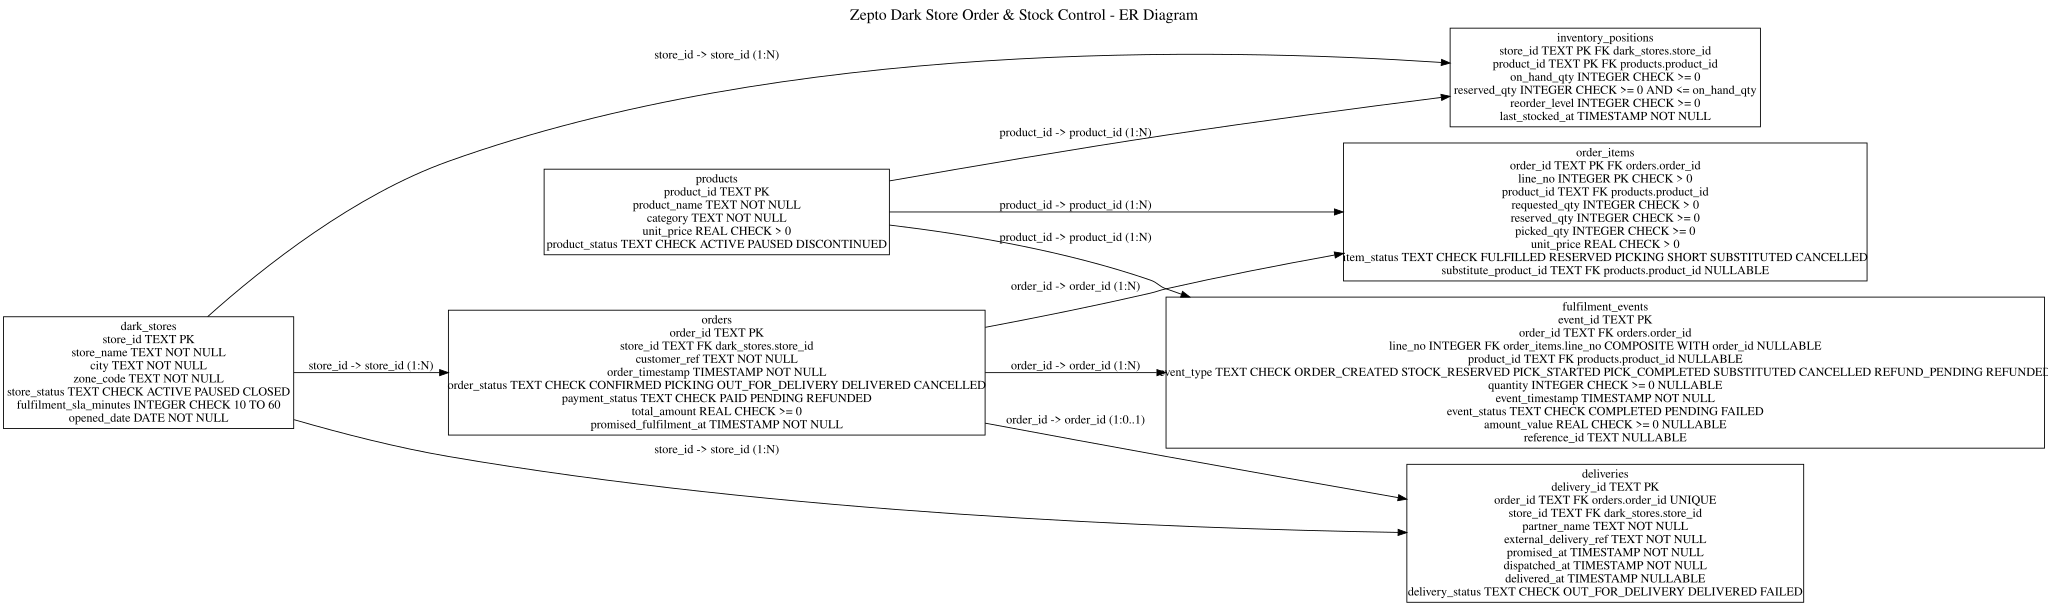

ER-1: Passed | Seven tables, key markers and nine relationships validated.


True

In [12]:
# SQL DEVELOPER WORKSPACE - ER-1
# TODO: Complete the seven table definitions and relationship list.
developer_tables = {
  "dark_stores": [
    "store_id TEXT PK",
    "store_name TEXT NOT NULL",
    "city TEXT NOT NULL",
    "zone_code TEXT NOT NULL",
    "store_status TEXT CHECK ACTIVE PAUSED CLOSED",
    "fulfilment_sla_minutes INTEGER CHECK 10 TO 60",
    "opened_date DATE NOT NULL"
  ],
  "products": [
    "product_id TEXT PK",
    "product_name TEXT NOT NULL",
    "category TEXT NOT NULL",
    "unit_price REAL CHECK > 0",
    "product_status TEXT CHECK ACTIVE PAUSED DISCONTINUED"
  ],
  "inventory_positions": [
    "store_id TEXT PK FK dark_stores.store_id",
    "product_id TEXT PK FK products.product_id",
    "on_hand_qty INTEGER CHECK >= 0",
    "reserved_qty INTEGER CHECK >= 0 AND <= on_hand_qty",
    "reorder_level INTEGER CHECK >= 0",
    "last_stocked_at TIMESTAMP NOT NULL"
  ],
  "orders": [
    "order_id TEXT PK",
    "store_id TEXT FK dark_stores.store_id",
    "customer_ref TEXT NOT NULL",
    "order_timestamp TIMESTAMP NOT NULL",
    "order_status TEXT CHECK CONFIRMED PICKING OUT_FOR_DELIVERY DELIVERED CANCELLED",
    "payment_status TEXT CHECK PAID PENDING REFUNDED",
    "total_amount REAL CHECK >= 0",
    "promised_fulfilment_at TIMESTAMP NOT NULL"
  ],
  "order_items": [
    "order_id TEXT PK FK orders.order_id",
    "line_no INTEGER PK CHECK > 0",
    "product_id TEXT FK products.product_id",
    "requested_qty INTEGER CHECK > 0",
    "reserved_qty INTEGER CHECK >= 0",
    "picked_qty INTEGER CHECK >= 0",
    "unit_price REAL CHECK > 0",
    "item_status TEXT CHECK FULFILLED RESERVED PICKING SHORT SUBSTITUTED CANCELLED",
    "substitute_product_id TEXT FK products.product_id NULLABLE"
  ],
  "fulfilment_events": [
    "event_id TEXT PK",
    "order_id TEXT FK orders.order_id",
    "line_no INTEGER FK order_items.line_no COMPOSITE WITH order_id NULLABLE",
    "product_id TEXT FK products.product_id NULLABLE",
    "event_type TEXT CHECK ORDER_CREATED STOCK_RESERVED PICK_STARTED PICK_COMPLETED SUBSTITUTED CANCELLED REFUND_PENDING REFUNDED",
    "quantity INTEGER CHECK >= 0 NULLABLE",
    "event_timestamp TIMESTAMP NOT NULL",
    "event_status TEXT CHECK COMPLETED PENDING FAILED",
    "amount_value REAL CHECK >= 0 NULLABLE",
    "reference_id TEXT NULLABLE"
  ],
  "deliveries": [
    "delivery_id TEXT PK",
    "order_id TEXT FK orders.order_id UNIQUE",
    "store_id TEXT FK dark_stores.store_id",
    "partner_name TEXT NOT NULL",
    "external_delivery_ref TEXT NOT NULL",
    "promised_at TIMESTAMP NOT NULL",
    "dispatched_at TIMESTAMP NOT NULL",
    "delivered_at TIMESTAMP NULLABLE",
    "delivery_status TEXT CHECK OUT_FOR_DELIVERY DELIVERED FAILED"
  ]
}
developer_relationships = [
  [
    "dark_stores",
    "store_id",
    "inventory_positions",
    "store_id",
    "1:N"
  ],
  [
    "products",
    "product_id",
    "inventory_positions",
    "product_id",
    "1:N"
  ],
  [
    "dark_stores",
    "store_id",
    "orders",
    "store_id",
    "1:N"
  ],
  [
    "orders",
    "order_id",
    "order_items",
    "order_id",
    "1:N"
  ],
  [
    "products",
    "product_id",
    "order_items",
    "product_id",
    "1:N"
  ],
  [
    "orders",
    "order_id",
    "fulfilment_events",
    "order_id",
    "1:N"
  ],
  [
    "products",
    "product_id",
    "fulfilment_events",
    "product_id",
    "1:N"
  ],
  [
    "orders",
    "order_id",
    "deliveries",
    "order_id",
    "1:0..1"
  ],
  [
    "dark_stores",
    "store_id",
    "deliveries",
    "store_id",
    "1:N"
  ]
]

validate_er_design(developer_tables, developer_relationships)


### Expected Output - ER-1

- `ER-1: Passed`
- Exactly seven connected table boxes
- Composite keys visible for `inventory_positions(store_id, product_id)` and `order_items(order_id, line_no)`
- Primary and foreign-key relationships rendered automatically

**Hint:** Mark key fields using `PK`, `FK`, and `NOT NULL` tokens in the supplied string format.


# 3. API Operations

The internal API is already running. The SQL Developer consumes it; the server is not part of the editable work.


In [13]:
display(api_documentation)


,Method,Endpoint,Purpose,Expected status
0,GET,/dark_stores,Read dark-store master records,200
1,GET,/products,Read product master records,200
2,GET,/inventory_positions,Read stock positions,200
3,GET,/orders,Read orders; supports filters and limit,200
4,GET,/orders/{id},Read one order,200 / 404
5,POST,/orders,Create one practice order,201 / 400 / 409
6,PUT,/orders/{id},Completely replace a practice order,200 / 400 / 404
7,PATCH,/orders/{id},Update selected practice-order fields,200 / 404
8,DELETE,/orders/{id},Delete one practice order,200 / 404
9,GET,/order_items,Read order item lines,200


## API-Q1 - Fetch Filtered Orders

**Business requirement:** Dark Store Operations needs a small review sample of delivered, paid orders.

Fetch exactly five orders using a `GET` request with `limit=5`, `order_status=DELIVERED`, and `payment_status=PAID`.


In [14]:
# SQL DEVELOPER WORKSPACE - API-Q1
api_q1_response = requests.get(f"{API_BASE_URL}/orders", params={"limit":5,"order_status":"DELIVERED","payment_status":"PAID"}, timeout=10)
# TODO: Write requests.get(...) with params and timeout=10.

if api_q1_response is None:
    set_status("API-Q1",False,"Add the filtered GET request.")
else:
    try:
        rows=api_q1_response.json(); display(pd.DataFrame(rows))
        ok=(api_q1_response.status_code==200 and len(rows)==5 and all(r.get("order_status")=="DELIVERED" and r.get("payment_status")=="PAID" for r in rows))
        set_status("API-Q1",ok,f"HTTP {api_q1_response.status_code}; records={len(rows)}")
    except Exception as exc: set_status("API-Q1",False,str(exc))


,order_id,store_id,customer_ref,order_timestamp,order_status,payment_status,total_amount,promised_fulfilment_at
0,ORD00001,DS009,CUST107919,2026-07-12 07:37:00,DELIVERED,PAID,1919.0,2026-07-12 08:02:00
1,ORD00002,DS002,CUST115838,2026-07-23 08:14:00,DELIVERED,PAID,1578.0,2026-07-23 08:38:00
2,ORD00003,DS007,CUST123757,2026-07-03 08:51:00,DELIVERED,PAID,3628.0,2026-07-03 09:10:00
3,ORD00004,DS012,CUST131676,2026-07-14 09:28:00,DELIVERED,PAID,940.5,2026-07-14 09:52:00
4,ORD00005,DS005,CUST139595,2026-07-25 10:05:00,DELIVERED,PAID,2468.0,2026-07-25 10:28:00


API-Q1: Passed | HTTP 200; records=5


### Expected Output - API-Q1

| Check | Expected |
|---|---|
| HTTP status | `200` |
| Records | `5` |
| `order_status` | `DELIVERED` for every record |
| `payment_status` | `PAID` for every record |

**Hint:** Use `requests.get(..., params={...}, timeout=10)`.


## API-Q2 - Create an Order with POST

Create the provided practice order. The setup resets this ID so the activity remains rerunnable.


In [15]:
# SQL DEVELOPER WORKSPACE - API-Q2
post_order_payload={"order_id":"ORD-API-POST","store_id":"DS004","customer_ref":"CUST900004","order_timestamp":"2026-07-31 19:20:00","order_status":"CONFIRMED","payment_status":"PAID","total_amount":275.75,"promised_fulfilment_at":"2026-07-31 19:45:00"}
reset_post_order(post_order_payload["order_id"])
api_q2_response = requests.post(f"{API_BASE_URL}/orders", json=post_order_payload, timeout=10)
# TODO: Write requests.post(...) using json=post_order_payload and timeout=10.

if api_q2_response is None: set_status("API-Q2",False,"Add the POST request.")
else:
    try:
        body=api_q2_response.json(); display(pd.DataFrame([body]))
        ok=(api_q2_response.status_code==201 and body==post_order_payload)
        set_status("API-Q2",ok,f"HTTP {api_q2_response.status_code}")
    except Exception as exc: set_status("API-Q2",False,str(exc))


,order_id,store_id,customer_ref,order_timestamp,order_status,payment_status,total_amount,promised_fulfilment_at
0,ORD-API-POST,DS004,CUST900004,2026-07-31 19:20:00,CONFIRMED,PAID,275.75,2026-07-31 19:45:00


API-Q2: Passed | HTTP 201


### Expected Output - API-Q2

- HTTP `201`
- `order_id = ORD-API-POST`
- Returned fields match the provided payload exactly

**Hint:** Use `requests.post(..., json=post_order_payload, timeout=10)`.


## API-Q3 - Replace a Complete Order with PUT

Reset `ORD-API-PUT`, then completely replace its editable content with the provided replacement payload.


In [16]:
# SQL DEVELOPER WORKSPACE - API-Q3
reset_practice_order("ORD-API-PUT")
put_payload={"store_id":"DS005","customer_ref":"CUST910005","order_timestamp":"2026-07-31 20:00:00","order_status":"PICKING","payment_status":"PAID","total_amount":620.25,"promised_fulfilment_at":"2026-07-31 20:24:00"}
api_q3_response = requests.put(f"{API_BASE_URL}/orders/ORD-API-PUT", json=put_payload, timeout=10)
# TODO: Write requests.put(...) using json=put_payload and timeout=10.

if api_q3_response is None: set_status("API-Q3",False,"Add the complete PUT request.")
else:
    try:
        body=api_q3_response.json(); display(pd.DataFrame([body]))
        expected={"order_id":"ORD-API-PUT",**put_payload}
        ok=(api_q3_response.status_code==200 and body==expected and set(body.keys())==set(expected.keys()))
        set_status("API-Q3",ok,f"HTTP {api_q3_response.status_code}")
    except Exception as exc: set_status("API-Q3",False,str(exc))


,order_id,order_status,order_timestamp,payment_status,promised_fulfilment_at,customer_ref,store_id,total_amount
0,ORD-API-PUT,PICKING,2026-07-31 20:00:00,PAID,2026-07-31 20:24:00,CUST910005,DS005,620.25


API-Q3: Passed | HTTP 200


### Expected Output - API-Q3

- HTTP `200`
- Returned order equals `order_id` plus every replacement field
- No fields from the original practice record remain unexpectedly

**Hint:** `PUT` represents complete replacement of the editable resource fields.


## API-Q4 - Update Selected Fields with PATCH

Reset `ORD-API-PATCH`. Change only `order_status` to `PICKING` and `payment_status` to `PAID`. All untargeted fields must remain unchanged.


In [17]:
# SQL DEVELOPER WORKSPACE - API-Q4
reset_practice_order("ORD-API-PATCH")
before_patch=copy.deepcopy(api_orders["ORD-API-PATCH"])
patch_payload={"order_status":"PICKING","payment_status":"PAID"}
api_q4_response = requests.patch(f"{API_BASE_URL}/orders/ORD-API-PATCH", json=patch_payload, timeout=10)
# TODO: Write requests.patch(...) using json=patch_payload and timeout=10.

if api_q4_response is None: set_status("API-Q4",False,"Add the PATCH request.")
else:
    try:
        body=api_q4_response.json(); display(pd.DataFrame([body]))
        unchanged=[k for k in before_patch if k not in patch_payload and body.get(k)==before_patch.get(k)]
        ok=(api_q4_response.status_code==200 and all(body.get(k)==v for k,v in patch_payload.items()) and len(unchanged)==len(before_patch)-len(patch_payload))
        set_status("API-Q4",ok,f"HTTP {api_q4_response.status_code}")
    except Exception as exc: set_status("API-Q4",False,str(exc))


,order_id,store_id,customer_ref,order_timestamp,order_status,payment_status,total_amount,promised_fulfilment_at
0,ORD-API-PATCH,DS002,CUST900002,2026-07-31 19:05:00,PICKING,PAID,325.5,2026-07-31 19:28:00


API-Q4: Passed | HTTP 200


### Expected Output - API-Q4

- HTTP `200`
- `order_status = PICKING`
- `payment_status = PAID`
- Every untargeted field is unchanged

**Hint:** `PATCH` sends only the fields that should change.


## API-Q5 - GET -> DELETE -> GET Verification

Reset `ORD-API-DELETE`, read it, delete it, then fetch it again. Operational deletion must be proven by the final `404`.


In [18]:
# SQL DEVELOPER WORKSPACE - API-Q5
reset_practice_order("ORD-API-DELETE")
api_q5_get_before = requests.get(f"{API_BASE_URL}/orders/ORD-API-DELETE", timeout=10)
api_q5_delete = requests.delete(f"{API_BASE_URL}/orders/ORD-API-DELETE", timeout=10)
api_q5_get_after = requests.get(f"{API_BASE_URL}/orders/ORD-API-DELETE", timeout=10)
# TODO: Write requests.get(...), requests.delete(...), requests.get(...) using timeout=10.

responses=[api_q5_get_before,api_q5_delete,api_q5_get_after]
if any(r is None for r in responses): set_status("API-Q5",False,"Complete all three requests.")
else:
    codes=[r.status_code for r in responses]
    display(pd.DataFrame([["GET before",codes[0]],["DELETE",codes[1]],["GET after",codes[2]]],columns=["request","status_code"]))
    set_status("API-Q5",codes==[200,200,404],f"sequence={codes}")


,request,status_code
0,GET before,200
1,DELETE,200
2,GET after,404


API-Q5: Passed | sequence=[200, 200, 404]


### Expected Output - API-Q5

| Request | Expected status |
|---|---:|
| GET before delete | `200` |
| DELETE | `200` |
| GET after delete | `404` |

**Hint:** Use the same order URL for all three calls.


# 4. SQL Developer Questions

All business analysis in this section must be completed in SQL. Pandas is used only to display and validate SQL outputs.


In [19]:
schema_catalog = build_schema_catalog(conn)
display(schema_catalog)


,table_name,column_name,data_type,not_null,primary_key
0,dark_stores,store_id,TEXT,False,True
1,dark_stores,store_name,TEXT,True,False
2,dark_stores,city,TEXT,True,False
3,dark_stores,zone_code,TEXT,True,False
4,dark_stores,store_status,TEXT,True,False
...,...,...,...,...,...
75,api_ingestion_runs,extracted_at,TEXT,True,False
76,api_ingestion_runs,rows_received,INTEGER,True,False
77,api_ingestion_runs,rows_loaded,INTEGER,True,False
78,api_ingestion_runs,status,TEXT,True,False


## 4A. SQL Foundations and Multiple Tables


### Q1 - Largest delivered orders

**Stakeholder business requirement:** Dark Store Operations needs this output to control daily fulfilment quality and prioritize operational follow-up.

**Tables to use:** `orders, dark_stores`

**How to approach:** Filter delivered paid orders, join stores, sort by value descending, and limit to ten.


In [20]:
# SQL DEVELOPER WORKSPACE - Q1
q1_sql = """
-- TODO: Write the SQL for Q1 here.
SELECT o.order_id, s.store_name, s.city, o.total_amount, o.order_timestamp
FROM orders o JOIN dark_stores s ON s.store_id=o.store_id
WHERE o.order_status='DELIVERED' AND o.payment_status='PAID'
ORDER BY o.total_amount DESC, o.order_id LIMIT 10;
"""
q1_result = run_sql_activity("Q1", q1_sql)
display(q1_result)


,columns,row_count,result_signature
0,True,True,True


Q1: Passed | rows=10


,order_id,store_name,city,total_amount,order_timestamp
0,ORD00783,Zepto Hitech City,Hyderabad,6477.0,2026-07-27 09:51:00
1,ORD00087,Zepto Hitech City,Hyderabad,5758.0,2026-07-28 15:39:00
2,ORD00696,Zepto Powai,Mumbai,5025.0,2026-07-31 16:12:00
3,ORD00899,Zepto Baner,Pune,4825.0,2026-07-01 21:23:00
4,ORD00464,Zepto Banjara Hills,Hyderabad,4618.5,2026-07-21 08:08:00
5,ORD00348,Zepto Powai,Mumbai,4208.0,2026-07-16 11:36:00
6,ORD00174,Zepto Velachery,Chennai,4188.0,2026-07-24 09:18:00
7,ORD00725,Zepto Saket,Delhi NCR,4170.5,2026-07-09 19:05:00
8,ORD00159,Zepto Hitech City,Hyderabad,4160.5,2026-07-14 15:03:00
9,ORD00219,Zepto Hitech City,Hyderabad,4160.5,2026-07-23 07:03:00


#### Expected Output - Q1

| Check | Expected |
|---|---|
| Required columns | `order_id, store_name, city, total_amount, order_timestamp` |
| Expected row count | `10` |
| Stable first row / key result | `order_id=ORD00783; store_name=Zepto Hitech City; city=Hyderabad; total_amount=6477.0; order_timestamp=2026-07-27 09:51:00` |

**Hint:** JOIN, WHERE, ORDER BY, LIMIT


### Q2 - Store delivered-order totals with minimum volume

**Stakeholder business requirement:** Dark Store Operations needs this output to control daily fulfilment quality and prioritize operational follow-up.

**Tables to use:** `orders, dark_stores`

**How to approach:** Aggregate delivered paid orders by store, calculate count and value, then apply HAVING thresholds.


In [21]:
# SQL DEVELOPER WORKSPACE - Q2
q2_sql = """
-- TODO: Write the SQL for Q2 here.
SELECT s.store_id,s.store_name,COUNT(*) AS delivered_orders,ROUND(SUM(o.total_amount),2) AS delivered_value
FROM orders o JOIN dark_stores s ON s.store_id=o.store_id
WHERE o.order_status='DELIVERED' AND o.payment_status='PAID'
GROUP BY s.store_id,s.store_name
HAVING COUNT(*)>=30
ORDER BY delivered_value DESC,s.store_id;
"""
q2_result = run_sql_activity("Q2", q2_sql)
display(q2_result)


,columns,row_count,result_signature
0,True,True,True


Q2: Passed | rows=12


,store_id,store_name,delivered_orders,delivered_value
0,DS003,Zepto Andheri,50,175842.5
1,DS007,Zepto Hitech City,49,163360.0
2,DS006,Zepto Gurugram Sector 43,50,146379.0
3,DS005,Zepto Saket,48,119253.0
4,DS009,Zepto Adyar,49,106495.5
5,DS010,Zepto Velachery,48,103532.0
6,DS011,Zepto Baner,49,101100.5
7,DS001,Zepto Indiranagar,49,87348.0
8,DS002,Zepto Koramangala,50,86546.0
9,DS004,Zepto Powai,47,84716.5


#### Expected Output - Q2

| Check | Expected |
|---|---|
| Required columns | `store_id, store_name, delivered_orders, delivered_value` |
| Expected row count | `12` |
| Stable first row / key result | `store_id=DS003; store_name=Zepto Andheri; delivered_orders=50; delivered_value=175842.5` |

**Hint:** GROUP BY, SUM, COUNT, HAVING


### Q3 - Orders affected by stock shortage or partial picking

**Stakeholder business requirement:** Dark Store Operations needs this output to control daily fulfilment quality and prioritize operational follow-up.

**Tables to use:** `orders, order_items, dark_stores`

**How to approach:** Roll up requested, reserved, and picked quantities; classify gaps with CASE and COALESCE-safe logic.


In [22]:
# SQL DEVELOPER WORKSPACE - Q3
q3_sql = """
-- TODO: Write the SQL for Q3 here.
WITH item_totals AS (
 SELECT order_id,SUM(requested_qty) AS requested_qty,SUM(reserved_qty) AS reserved_qty,SUM(picked_qty) AS picked_qty
 FROM order_items GROUP BY order_id
)
SELECT o.order_id,s.store_name,i.requested_qty,i.reserved_qty,i.picked_qty,
 CASE WHEN i.reserved_qty<i.requested_qty THEN 'SHORT'
      WHEN i.picked_qty<i.reserved_qty THEN 'PARTIAL_PICK' ELSE 'FULFILLED' END AS fulfilment_state
FROM orders o JOIN dark_stores s ON s.store_id=o.store_id JOIN item_totals i ON i.order_id=o.order_id
WHERE o.order_status<>'CANCELLED' AND (i.reserved_qty<i.requested_qty OR i.picked_qty<i.reserved_qty)
ORDER BY o.order_id LIMIT 20;
"""
q3_result = run_sql_activity("Q3", q3_sql)
display(q3_result)


,columns,row_count,result_signature
0,True,True,True


Q3: Passed | rows=20


,order_id,store_name,requested_qty,reserved_qty,picked_qty,fulfilment_state
0,ORD00028,Zepto Kharadi,5,5,4,PARTIAL_PICK
1,ORD00029,Zepto Saket,13,10,10,SHORT
2,ORD00044,Zepto Banjara Hills,5,5,4,PARTIAL_PICK
3,ORD00056,Zepto Banjara Hills,5,5,4,PARTIAL_PICK
4,ORD00084,Zepto Powai,5,5,4,PARTIAL_PICK
5,ORD00087,Zepto Hitech City,18,15,15,SHORT
6,ORD00088,Zepto Kharadi,5,5,4,PARTIAL_PICK
7,ORD00112,Zepto Kharadi,5,5,4,PARTIAL_PICK
8,ORD00132,Zepto Powai,5,5,4,PARTIAL_PICK
9,ORD00140,Zepto Banjara Hills,5,5,4,PARTIAL_PICK


#### Expected Output - Q3

| Check | Expected |
|---|---|
| Required columns | `order_id, store_name, requested_qty, reserved_qty, picked_qty, fulfilment_state` |
| Expected row count | `20` |
| Stable first row / key result | `order_id=ORD00028; store_name=Zepto Kharadi; requested_qty=5; reserved_qty=5; picked_qty=4; fulfilment_state=PARTIAL_PICK` |

**Hint:** CTE, JOIN, SUM, CASE


### Q4 - Out-for-delivery orders missing delivery records

**Stakeholder business requirement:** Dark Store Operations needs this output to control daily fulfilment quality and prioritize operational follow-up.

**Tables to use:** `orders, dark_stores, deliveries`

**How to approach:** LEFT JOIN delivery records and keep rows where the delivery side is NULL.


In [23]:
# SQL DEVELOPER WORKSPACE - Q4
q4_sql = """
-- TODO: Write the SQL for Q4 here.
SELECT o.order_id, s.store_name, o.order_status, o.order_timestamp
FROM orders o JOIN dark_stores s ON s.store_id=o.store_id
LEFT JOIN deliveries d ON d.order_id=o.order_id
WHERE o.order_status='OUT_FOR_DELIVERY' AND d.delivery_id IS NULL
ORDER BY o.order_timestamp, o.order_id;
"""
q4_result = run_sql_activity("Q4", q4_sql)
display(q4_result)


,columns,row_count,result_signature
0,True,True,True


Q4: Passed | rows=22


,order_id,store_name,order_status,order_timestamp
0,ORD00234,Zepto Velachery,OUT_FOR_DELIVERY,2026-07-02 16:18:00
1,ORD00468,Zepto Powai,OUT_FOR_DELIVERY,2026-07-03 10:36:00
2,ORD00702,Zepto Velachery,OUT_FOR_DELIVERY,2026-07-04 19:54:00
3,ORD00195,Zepto Hitech City,OUT_FOR_DELIVERY,2026-07-07 07:15:00
4,ORD00429,Zepto Indiranagar,OUT_FOR_DELIVERY,2026-07-08 16:33:00
5,ORD00897,Zepto Indiranagar,OUT_FOR_DELIVERY,2026-07-10 20:09:00
6,ORD00156,Zepto Powai,OUT_FOR_DELIVERY,2026-07-12 13:12:00
7,ORD00390,Zepto Velachery,OUT_FOR_DELIVERY,2026-07-13 07:30:00
8,ORD00624,Zepto Powai,OUT_FOR_DELIVERY,2026-07-14 16:48:00
9,ORD00858,Zepto Velachery,OUT_FOR_DELIVERY,2026-07-15 11:06:00


#### Expected Output - Q4

| Check | Expected |
|---|---|
| Required columns | `order_id, store_name, order_status, order_timestamp` |
| Expected row count | `22` |
| Stable first row / key result | `order_id=ORD00234; store_name=Zepto Velachery; order_status=OUT_FOR_DELIVERY; order_timestamp=2026-07-02 16:18:00` |

**Hint:** LEFT JOIN, IS NULL anti-join


## 4B. SQL Functions, Set Operations, Subqueries, and CTEs


### Q5 - Stores with both stock shortages and SLA exceptions

**Stakeholder business requirement:** The operations control team needs this result to identify stores, orders, or exception patterns that require intervention.

**Tables to use:** `operational_exceptions`

**How to approach:** Build the two store sets and return their intersection.


In [24]:
# SQL DEVELOPER WORKSPACE - Q5
q5_sql = """
-- TODO: Write the SQL for Q5 here.
SELECT store_id FROM operational_exceptions WHERE exception_type='STOCK_SHORTAGE'
INTERSECT
SELECT store_id FROM operational_exceptions WHERE exception_type IN ('PICK_SLA_BREACH','DELIVERY_SLA_BREACH')
ORDER BY store_id;
"""
q5_result = run_sql_activity("Q5", q5_sql)
display(q5_result)


,columns,row_count,result_signature
0,True,True,True


Q5: Passed | rows=6


,store_id
0,DS001
1,DS003
2,DS005
3,DS007
4,DS009
5,DS011


#### Expected Output - Q5

| Check | Expected |
|---|---|
| Required columns | `store_id` |
| Expected row count | `6` |
| Stable first row / key result | `store_id=DS001` |

**Hint:** INTERSECT


### Q6 - Store operations risk report

**Stakeholder business requirement:** The operations control team needs this result to identify stores, orders, or exception patterns that require intervention.

**Tables to use:** `dark_stores, operational_exceptions`

**How to approach:** Aggregate open exceptions, then format labels and derive a risk band using SQL functions.


In [25]:
# SQL DEVELOPER WORKSPACE - Q6
q6_sql = """
-- TODO: Write the SQL for Q6 here.
WITH open_counts AS (SELECT store_id,COUNT(*) AS open_exceptions FROM operational_exceptions WHERE status='OPEN' GROUP BY store_id)
SELECT s.store_id,UPPER(s.store_name) AS store_label,SUBSTR(s.zone_code,1,3) AS zone_code,
 CAST(julianday('2026-08-01')-julianday(s.opened_date) AS INTEGER) AS operating_days,
 COALESCE(c.open_exceptions,0) AS open_exceptions,
 CASE WHEN COALESCE(c.open_exceptions,0)>=15 THEN 'HIGH'
      WHEN COALESCE(c.open_exceptions,0)>=8 THEN 'MEDIUM' ELSE 'LOW' END AS risk_band
FROM dark_stores s LEFT JOIN open_counts c ON c.store_id=s.store_id
ORDER BY open_exceptions DESC,s.store_id;
"""
q6_result = run_sql_activity("Q6", q6_sql)
display(q6_result)


,columns,row_count,result_signature
0,True,True,True


Q6: Passed | rows=12


,store_id,store_label,zone_code,operating_days,open_exceptions,risk_band
0,DS007,ZEPTO HITECH CITY,Z01,875,24,HIGH
1,DS001,ZEPTO INDIRANAGAR,Z01,878,22,HIGH
2,DS005,ZEPTO SAKET,Z05,248,22,HIGH
3,DS009,ZEPTO ADYAR,Z03,1109,22,HIGH
4,DS003,ZEPTO ANDHERI,Z03,1112,21,HIGH
5,DS011,ZEPTO BANER,Z05,272,21,HIGH
6,DS004,ZEPTO POWAI,Z04,679,17,HIGH
7,DS008,ZEPTO BANJARA HILLS,Z02,444,16,HIGH
8,DS012,ZEPTO KHARADI,Z06,1302,16,HIGH
9,DS002,ZEPTO KORAMANGALA,Z02,447,15,HIGH


#### Expected Output - Q6

| Check | Expected |
|---|---|
| Required columns | `store_id, store_label, zone_code, operating_days, open_exceptions, risk_band` |
| Expected row count | `12` |
| Stable first row / key result | `store_id=DS007; store_label=ZEPTO HITECH CITY; zone_code=Z01; operating_days=875; open_exceptions=24; risk_band=HIGH` |

**Hint:** UPPER, SUBSTR, date calculation, CAST, COALESCE, CASE


### Q7 - Stores above average delivered order value

**Stakeholder business requirement:** The operations control team needs this result to identify stores, orders, or exception patterns that require intervention.

**Tables to use:** `orders, dark_stores`

**How to approach:** Calculate store delivered value, compare each store against the scalar average, then sort descending.


In [26]:
# SQL DEVELOPER WORKSPACE - Q7
q7_sql = """
-- TODO: Write the SQL for Q7 here.
WITH store_values AS (
 SELECT s.store_id,s.store_name,ROUND(SUM(o.total_amount),2) AS delivered_value
 FROM dark_stores s JOIN orders o ON o.store_id=s.store_id
 WHERE o.order_status='DELIVERED' AND o.payment_status='PAID'
 GROUP BY s.store_id,s.store_name
)
SELECT store_id,store_name,delivered_value FROM store_values
WHERE delivered_value>(SELECT AVG(delivered_value) FROM store_values)
ORDER BY delivered_value DESC,store_id;
"""
q7_result = run_sql_activity("Q7", q7_sql)
display(q7_result)


,columns,row_count,result_signature
0,True,True,True


Q7: Passed | rows=4


,store_id,store_name,delivered_value
0,DS003,Zepto Andheri,175842.5
1,DS007,Zepto Hitech City,163360.0
2,DS006,Zepto Gurugram Sector 43,146379.0
3,DS005,Zepto Saket,119253.0


#### Expected Output - Q7

| Check | Expected |
|---|---|
| Required columns | `store_id, store_name, delivered_value` |
| Expected row count | `4` |
| Stable first row / key result | `store_id=DS003; store_name=Zepto Andheri; delivered_value=175842.5` |

**Hint:** CTE, scalar subquery


### Q8 - Recalculate fulfilment state from item and event evidence

**Stakeholder business requirement:** The operations control team needs this result to identify stores, orders, or exception patterns that require intervention.

**Tables to use:** `orders, order_items, fulfilment_events`

**How to approach:** Use multiple standard CTEs for item rollup, event rollup, and classification; return only mismatches or incomplete fulfilment.


In [27]:
# SQL DEVELOPER WORKSPACE - Q8
q8_sql = """
-- TODO: Write the SQL for Q8 here.
WITH item_rollup AS (
 SELECT order_id,SUM(requested_qty) AS requested_qty,SUM(reserved_qty) AS reserved_qty,SUM(picked_qty) AS picked_qty
 FROM order_items GROUP BY order_id
), event_rollup AS (
 SELECT order_id,
 MAX(CASE WHEN event_type='CANCELLED' THEN 1 ELSE 0 END) AS cancelled,
 MAX(CASE WHEN event_type='PICK_COMPLETED' THEN 1 ELSE 0 END) AS pick_completed,
 MAX(CASE WHEN event_type='STOCK_RESERVED' THEN 1 ELSE 0 END) AS reserved
 FROM fulfilment_events GROUP BY order_id
), classified AS (
 SELECT o.order_id,o.order_status,
 CASE WHEN o.order_status='CANCELLED' OR COALESCE(e.cancelled,0)=1 THEN 'CANCELLED'
 WHEN i.reserved_qty<i.requested_qty THEN 'SHORT'
 WHEN i.picked_qty<i.reserved_qty THEN 'PARTIAL_PICK'
 WHEN COALESCE(e.pick_completed,0)=1 THEN 'PICKED'
 WHEN COALESCE(e.reserved,0)=1 THEN 'RESERVED' ELSE 'NEW' END AS calculated_state,
 i.requested_qty,i.reserved_qty,i.picked_qty
 FROM orders o JOIN item_rollup i ON i.order_id=o.order_id LEFT JOIN event_rollup e ON e.order_id=o.order_id
)
SELECT order_id,order_status,calculated_state,requested_qty,reserved_qty,picked_qty FROM classified
WHERE calculated_state IN ('SHORT','PARTIAL_PICK')
 OR (order_status='DELIVERED' AND calculated_state<>'PICKED')
ORDER BY order_id LIMIT 25;
"""
q8_result = run_sql_activity("Q8", q8_sql)
display(q8_result)


,columns,row_count,result_signature
0,True,True,True


Q8: Passed | rows=25


,order_id,order_status,calculated_state,requested_qty,reserved_qty,picked_qty
0,ORD00028,CONFIRMED,PARTIAL_PICK,5,5,4
1,ORD00029,DELIVERED,SHORT,13,10,10
2,ORD00044,PICKING,PARTIAL_PICK,5,5,4
3,ORD00056,CONFIRMED,PARTIAL_PICK,5,5,4
4,ORD00084,CONFIRMED,PARTIAL_PICK,5,5,4
5,ORD00087,DELIVERED,SHORT,18,15,15
6,ORD00088,PICKING,PARTIAL_PICK,5,5,4
7,ORD00112,CONFIRMED,PARTIAL_PICK,5,5,4
8,ORD00132,PICKING,PARTIAL_PICK,5,5,4
9,ORD00140,CONFIRMED,PARTIAL_PICK,5,5,4


#### Expected Output - Q8

| Check | Expected |
|---|---|
| Required columns | `order_id, order_status, calculated_state, requested_qty, reserved_qty, picked_qty` |
| Expected row count | `25` |
| Stable first row / key result | `order_id=ORD00028; order_status=CONFIRMED; calculated_state=PARTIAL_PICK; requested_qty=5; reserved_qty=5; picked_qty=4` |

**Hint:** Multiple standard CTEs; no recursion


## 4C. Window Functions


### Q9 - Rank dark stores by fulfilment rate within each city

**Stakeholder business requirement:** Product and Operations need a comparable performance view over time and across dark stores.

**Tables to use:** `dark_stores, orders`

**How to approach:** Calculate store fulfilment rates then rank stores separately inside each city.


In [28]:
# SQL DEVELOPER WORKSPACE - Q9
q9_sql = """
-- TODO: Write the SQL for Q9 here.
WITH store_rates AS (
 SELECT s.city,s.store_id,s.store_name,COUNT(o.order_id) AS total_orders,
 SUM(CASE WHEN o.order_status='DELIVERED' THEN 1 ELSE 0 END) AS delivered_orders,
 ROUND(100.0*SUM(CASE WHEN o.order_status='DELIVERED' THEN 1 ELSE 0 END)/NULLIF(COUNT(o.order_id),0),2) AS fulfilment_rate
 FROM dark_stores s LEFT JOIN orders o ON o.store_id=s.store_id GROUP BY s.store_id,s.store_name,s.city
)
SELECT city,store_id,store_name,total_orders,delivered_orders,fulfilment_rate,
 RANK() OVER(PARTITION BY city ORDER BY fulfilment_rate DESC) AS city_rank
FROM store_rates ORDER BY city,city_rank,store_id;
"""
q9_result = run_sql_activity("Q9", q9_sql)
display(q9_result)


,columns,row_count,result_signature
0,True,True,True


Q9: Passed | rows=12


,city,store_id,store_name,total_orders,delivered_orders,fulfilment_rate,city_rank
0,Bengaluru,DS001,Zepto Indiranagar,75,52,69.33,1
1,Bengaluru,DS002,Zepto Koramangala,75,51,68.00,2
2,Chennai,DS010,Zepto Velachery,75,51,68.00,1
3,Chennai,DS009,Zepto Adyar,75,50,66.67,2
4,Delhi NCR,DS006,Zepto Gurugram Sector 43,75,52,69.33,1
5,Delhi NCR,DS005,Zepto Saket,75,50,66.67,2
6,Hyderabad,DS008,Zepto Banjara Hills,75,51,68.00,1
7,Hyderabad,DS007,Zepto Hitech City,75,50,66.67,2
8,Mumbai,DS003,Zepto Andheri,75,52,69.33,1
9,Mumbai,DS004,Zepto Powai,75,50,66.67,2


#### Expected Output - Q9

| Check | Expected |
|---|---|
| Required columns | `city, store_id, store_name, total_orders, delivered_orders, fulfilment_rate, city_rank` |
| Expected row count | `12` |
| Stable first row / key result | `city=Bengaluru; store_id=DS001; store_name=Zepto Indiranagar; total_orders=75; delivered_orders=52; fulfilment_rate=69.33; city_rank=1` |

**Hint:** RANK, PARTITION BY


### Q10 - Daily delivered value, running total, and seven-day moving average

**Stakeholder business requirement:** Product and Operations need a comparable performance view over time and across dark stores.

**Tables to use:** `orders`

**How to approach:** Aggregate to daily delivered value first, then apply window frames for cumulative and rolling metrics.


In [29]:
# SQL DEVELOPER WORKSPACE - Q10
q10_sql = """
-- TODO: Write the SQL for Q10 here.
WITH daily AS (
 SELECT DATE(order_timestamp) AS order_date,ROUND(SUM(total_amount),2) AS delivered_value
 FROM orders WHERE order_status='DELIVERED' AND payment_status='PAID' GROUP BY DATE(order_timestamp)
)
SELECT order_date,delivered_value,
 ROUND(SUM(delivered_value) OVER(ORDER BY order_date ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW),2) AS running_value,
 ROUND(AVG(delivered_value) OVER(ORDER BY order_date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW),2) AS moving_7d_avg
FROM daily ORDER BY order_date;
"""
q10_result = run_sql_activity("Q10", q10_sql)
display(q10_result)


,columns,row_count,result_signature
0,True,True,True


Q10: Passed | rows=31


,order_date,delivered_value,running_value,moving_7d_avg
0,2026-07-01,43291.5,43291.5,43291.50
1,2026-07-02,40114.0,83405.5,41702.75
2,2026-07-03,39402.0,122807.5,40935.83
3,2026-07-04,39178.0,161985.5,40496.38
4,2026-07-05,37421.0,199406.5,39881.30
5,2026-07-06,40848.0,240254.5,40042.42
6,2026-07-07,36171.0,276425.5,39489.36
7,2026-07-08,41488.5,317914.0,39231.79
8,2026-07-09,43822.5,361736.5,39761.57
9,2026-07-10,44892.0,406628.5,40545.86


#### Expected Output - Q10

| Check | Expected |
|---|---|
| Required columns | `order_date, delivered_value, running_value, moving_7d_avg` |
| Expected row count | `31` |
| Stable first row / key result | `order_date=2026-07-01; delivered_value=43291.5; running_value=43291.5; moving_7d_avg=43291.5` |

**Hint:** SUM/AVG window frames


### Q11 - Day-over-day delivered value comparison

**Stakeholder business requirement:** Product and Operations need a comparable performance view over time and across dark stores.

**Tables to use:** `orders`

**How to approach:** Aggregate daily value, use LAG for the prior day, then calculate percentage change safely.


In [30]:
# SQL DEVELOPER WORKSPACE - Q11
q11_sql = """
-- TODO: Write the SQL for Q11 here.
WITH daily AS (
 SELECT DATE(order_timestamp) AS order_date,ROUND(SUM(total_amount),2) AS delivered_value
 FROM orders WHERE order_status='DELIVERED' AND payment_status='PAID' GROUP BY DATE(order_timestamp)
), compared AS (
 SELECT order_date,delivered_value,LAG(delivered_value) OVER(ORDER BY order_date) AS previous_day_value FROM daily
)
SELECT order_date,delivered_value,previous_day_value,
 CASE WHEN previous_day_value IS NULL OR previous_day_value=0 THEN NULL
 ELSE ROUND(100.0*(delivered_value-previous_day_value)/previous_day_value,2) END AS pct_change
FROM compared ORDER BY order_date;
"""
q11_result = run_sql_activity("Q11", q11_sql)
display(q11_result)


,columns,row_count,result_signature
0,True,True,True


Q11: Passed | rows=31


,order_date,delivered_value,previous_day_value,pct_change
0,2026-07-01,43291.5,NaN,NaN
1,2026-07-02,40114.0,43291.5,-7.34
2,2026-07-03,39402.0,40114.0,-1.77
3,2026-07-04,39178.0,39402.0,-0.57
4,2026-07-05,37421.0,39178.0,-4.48
5,2026-07-06,40848.0,37421.0,9.16
6,2026-07-07,36171.0,40848.0,-11.45
7,2026-07-08,41488.5,36171.0,14.70
8,2026-07-09,43822.5,41488.5,5.63
9,2026-07-10,44892.0,43822.5,2.44


#### Expected Output - Q11

| Check | Expected |
|---|---|
| Required columns | `order_date, delivered_value, previous_day_value, pct_change` |
| Expected row count | `31` |
| Stable first row / key result | `order_date=2026-07-01; delivered_value=43291.5; previous_day_value=None; pct_change=None` |

**Hint:** LAG, CASE


### Q12 - First and latest paid order for every dark store

**Stakeholder business requirement:** Product and Operations need a comparable performance view over time and across dark stores.

**Tables to use:** `orders, dark_stores`

**How to approach:** Use ROW_NUMBER in ascending and descending order, then conditional aggregation.


In [31]:
# SQL DEVELOPER WORKSPACE - Q12
q12_sql = """
-- TODO: Write the SQL for Q12 here.
WITH ranked AS (
 SELECT order_id,store_id,order_timestamp,
 ROW_NUMBER() OVER(PARTITION BY store_id ORDER BY order_timestamp,order_id) AS first_rank,
 ROW_NUMBER() OVER(PARTITION BY store_id ORDER BY order_timestamp DESC,order_id DESC) AS latest_rank
 FROM orders WHERE payment_status='PAID'
)
SELECT s.store_id,s.store_name,
 MAX(CASE WHEN r.first_rank=1 THEN r.order_id END) AS first_order_id,
 MAX(CASE WHEN r.first_rank=1 THEN r.order_timestamp END) AS first_order_timestamp,
 MAX(CASE WHEN r.latest_rank=1 THEN r.order_id END) AS latest_order_id,
 MAX(CASE WHEN r.latest_rank=1 THEN r.order_timestamp END) AS latest_order_timestamp
FROM dark_stores s LEFT JOIN ranked r ON r.store_id=s.store_id
GROUP BY s.store_id,s.store_name ORDER BY s.store_id;
"""
q12_result = run_sql_activity("Q12", q12_sql)
display(q12_result)


,columns,row_count,result_signature
0,True,True,True


Q12: Passed | rows=12


,store_id,store_name,first_order_id,first_order_timestamp,latest_order_id,latest_order_timestamp
0,DS001,Zepto Indiranagar,ORD00465,2026-07-01 08:45:00,ORD00045,2026-07-31 19:45:00
1,DS002,Zepto Koramangala,ORD00806,2026-07-01 09:02:00,ORD00386,2026-07-31 20:02:00
2,DS003,Zepto Andheri,ORD00031,2026-07-01 11:07:00,ORD00727,2026-07-31 20:19:00
3,DS004,Zepto Powai,ORD00372,2026-07-01 11:24:00,ORD00696,2026-07-31 16:12:00
4,DS005,Zepto Saket,ORD00341,2026-07-01 07:17:00,ORD00665,2026-07-31 12:05:00
5,DS006,Zepto Gurugram Sector 43,ORD00682,2026-07-01 07:34:00,ORD00262,2026-07-31 18:34:00
6,DS007,Zepto Hitech City,ORD00279,2026-07-01 14:03:00,ORD00603,2026-07-31 18:51:00
7,DS008,Zepto Banjara Hills,ORD00248,2026-07-01 09:56:00,ORD00572,2026-07-31 14:44:00
8,DS009,Zepto Adyar,ORD00589,2026-07-01 10:13:00,ORD00169,2026-07-31 21:13:00
9,DS010,Zepto Velachery,ORD00186,2026-07-01 16:42:00,ORD00882,2026-07-31 10:54:00


#### Expected Output - Q12

| Check | Expected |
|---|---|
| Required columns | `store_id, store_name, first_order_id, first_order_timestamp, latest_order_id, latest_order_timestamp` |
| Expected row count | `12` |
| Stable first row / key result | `store_id=DS001; store_name=Zepto Indiranagar; first_order_id=ORD00465; first_order_timestamp=2026-07-01 08:45:00; latest_order_id=ORD00045; latest_order_timestamp=2026-07-31 19:45:00` |

**Hint:** ROW_NUMBER, conditional aggregation


### Q13 - Top three operational-exception ranks per city with ties

**Stakeholder business requirement:** Product and Operations need a comparable performance view over time and across dark stores.

**Tables to use:** `operational_exceptions, dark_stores`

**How to approach:** Count exception categories by store, rank within city using DENSE_RANK, and retain ranks one to three.


In [32]:
# SQL DEVELOPER WORKSPACE - Q13
q13_sql = """
-- TODO: Write the SQL for Q13 here.
WITH counts AS (
 SELECT s.city,s.store_id,s.store_name,e.exception_type,COUNT(*) AS exception_count
 FROM operational_exceptions e JOIN dark_stores s ON s.store_id=e.store_id
 WHERE e.status='OPEN' GROUP BY s.city,s.store_id,s.store_name,e.exception_type
), ranked AS (
 SELECT *,DENSE_RANK() OVER(PARTITION BY city ORDER BY exception_count DESC) AS exception_rank FROM counts
)
SELECT city,store_id,store_name,exception_type,exception_count,exception_rank
FROM ranked WHERE exception_rank<=3 ORDER BY city,exception_rank,store_id,exception_type;
"""
q13_result = run_sql_activity("Q13", q13_sql)
display(q13_result)


,columns,row_count,result_signature
0,True,True,True


Q13: Passed | rows=32


,city,store_id,store_name,exception_type,exception_count,exception_rank
0,Bengaluru,DS002,Zepto Koramangala,RESERVATION_WITHOUT_PICK,9,1
1,Bengaluru,DS001,Zepto Indiranagar,RESERVATION_WITHOUT_PICK,8,2
2,Bengaluru,DS001,Zepto Indiranagar,CANCELLED_AFTER_RESERVATION,4,3
3,Bengaluru,DS001,Zepto Indiranagar,REFUND_PENDING,4,3
4,Bengaluru,DS002,Zepto Koramangala,CANCELLED_AFTER_RESERVATION,4,3
5,Chennai,DS009,Zepto Adyar,RESERVATION_WITHOUT_PICK,9,1
6,Chennai,DS010,Zepto Velachery,RESERVATION_WITHOUT_PICK,8,2
7,Chennai,DS009,Zepto Adyar,CANCELLED_AFTER_RESERVATION,4,3
8,Chennai,DS009,Zepto Adyar,REFUND_PENDING,4,3
9,Chennai,DS010,Zepto Velachery,CANCELLED_AFTER_RESERVATION,4,3


#### Expected Output - Q13

| Check | Expected |
|---|---|
| Required columns | `city, store_id, store_name, exception_type, exception_count, exception_rank` |
| Expected row count | `32` |
| Stable first row / key result | `city=Bengaluru; store_id=DS002; store_name=Zepto Koramangala; exception_type=RESERVATION_WITHOUT_PICK; exception_count=9; exception_rank=1` |

**Hint:** DENSE_RANK, filtering


# 5. Transaction Management


## T1 - Commit an Approved Stock Reservation Adjustment

An inventory controller approved a two-unit manual reservation for product `P0001` at store `DS001` while an order recovery is being completed. Use `BEGIN`, update the stock position, insert movement `MOV-DEVELOPER-COMMIT`, then `COMMIT`.


In [33]:
# SQL DEVELOPER WORKSPACE - T1
movement_id="MOV-DEVELOPER-COMMIT"; store_id="DS001"; product_id="P0001"; qty=2
conn.execute("DELETE FROM inventory_movements WHERE movement_id=?",(movement_id,)); conn.commit()
baseline=conn.execute("SELECT reserved_qty FROM inventory_positions WHERE store_id=? AND product_id=?",(store_id,product_id)).fetchone()[0]
# Reset to a known baseline if rerun after a prior successful attempt.
if baseline >= qty and globals().get("t1_last_baseline") is not None:
    conn.execute("UPDATE inventory_positions SET reserved_qty=? WHERE store_id=? AND product_id=?",(t1_last_baseline,store_id,product_id)); conn.commit(); baseline=t1_last_baseline

# TODO: Write BEGIN; UPDATE inventory_positions; INSERT inventory_movements; COMMIT.
t1_sql = """
BEGIN;
UPDATE inventory_positions SET reserved_qty=reserved_qty+2 WHERE store_id='DS001' AND product_id='P0001';
INSERT INTO inventory_movements (movement_id,store_id,product_id,order_id,movement_type,quantity_delta,movement_timestamp,reason)
VALUES ('MOV-DEVELOPER-COMMIT','DS001','P0001',NULL,'ADJUSTMENT',-2,'2026-08-01 08:00:00','Approved two-unit recovery reservation');
COMMIT;
"""
if not t1_sql.strip():
    set_status("T1",False,"Add the approved transaction script.")
else:
    trace=[]
    try:
        conn.set_trace_callback(trace.append)
        conn.executescript(t1_sql)
        conn.set_trace_callback(None)
        trace_ok,_=validate_transaction_trace(trace,"COMMIT",store_id,product_id,movement_id,qty)

        movement=conn.execute("SELECT store_id,product_id,movement_type,quantity_delta FROM inventory_movements WHERE movement_id=?",(movement_id,)).fetchone()
        after=conn.execute("SELECT reserved_qty FROM inventory_positions WHERE store_id=? AND product_id=?",(store_id,product_id)).fetchone()[0]
        movement_ok=(movement==(store_id,product_id,"ADJUSTMENT",-qty))
        state_ok=(after==baseline+qty)

        with sqlite3.connect(str(DB_PATH)) as verify_conn:
            persisted_movement=verify_conn.execute("SELECT store_id,product_id,movement_type,quantity_delta FROM inventory_movements WHERE movement_id=?",(movement_id,)).fetchone()
            persisted_reserved=verify_conn.execute("SELECT reserved_qty FROM inventory_positions WHERE store_id=? AND product_id=?",(store_id,product_id)).fetchone()[0]
        persisted_ok=(persisted_movement==(store_id,product_id,"ADJUSTMENT",-qty) and persisted_reserved==baseline+qty)
        checks={"trace_semantics":trace_ok,"movement_values":movement_ok,"current_connection_state":state_ok,"new_connection_commit_visibility":persisted_ok}
        display(pd.DataFrame([[k,v] for k,v in checks.items()],columns=["T1_validation_check","passed"]))
        ok=all(checks.values())
        if ok:
            t1_last_baseline=baseline
        else:
            if conn.in_transaction: conn.rollback()
            conn.execute("DELETE FROM inventory_movements WHERE movement_id=?",(movement_id,))
            conn.execute("UPDATE inventory_positions SET reserved_qty=? WHERE store_id=? AND product_id=?",(baseline,store_id,product_id)); conn.commit()
        set_status("T1",ok,f"trace={trace_ok}; movement={movement_ok}; reserved_qty={after}; persisted={persisted_ok}")
    except Exception as exc:
        try:
            conn.set_trace_callback(None)
            if conn.in_transaction: conn.rollback()
            conn.execute("DELETE FROM inventory_movements WHERE movement_id=?",(movement_id,))
            conn.execute("UPDATE inventory_positions SET reserved_qty=? WHERE store_id=? AND product_id=?",(baseline,store_id,product_id)); conn.commit()
        except Exception:
            pass
        set_status("T1",False,str(exc))


,transaction_trace_check,passed
0,BEGIN executed,True
1,inventory UPDATE executed,True
2,movement INSERT executed,True
3,COMMIT executed,True
4,required order,True
5,no opposite finalizer,True
6,reservation increment correct,True
7,update targets correct stock row,True
8,movement identifiers present,True


,T1_validation_check,passed
0,trace_semantics,True
1,movement_values,True
2,current_connection_state,True
3,new_connection_commit_visibility,True


T1: Passed | trace=True; movement=True; reserved_qty=3; persisted=True


### Expected Output - T1

- `MOV-DEVELOPER-COMMIT` remains in `inventory_movements`
- `reserved_qty` increases by exactly `2`
- Validation reports `T1: Passed`

**Hint:** A committed transaction preserves both the inventory update and its movement-history row.


## T2 - Roll Back an Unapproved Stock Reservation Adjustment

A temporary three-unit reservation for product `P0002` at store `DS002` has not been approved. Use `BEGIN`, apply the temporary update and movement `MOV-DEVELOPER-ROLLBACK`, then `ROLLBACK`.


In [34]:
# SQL DEVELOPER WORKSPACE - T2
movement_id="MOV-DEVELOPER-ROLLBACK"; store_id="DS002"; product_id="P0002"; qty=3
conn.execute("DELETE FROM inventory_movements WHERE movement_id=?",(movement_id,)); conn.commit()
baseline=conn.execute("SELECT reserved_qty FROM inventory_positions WHERE store_id=? AND product_id=?",(store_id,product_id)).fetchone()[0]
# TODO: Write BEGIN; UPDATE inventory_positions; INSERT inventory_movements; ROLLBACK.
t2_sql = """
BEGIN;
UPDATE inventory_positions SET reserved_qty=reserved_qty+3 WHERE store_id='DS002' AND product_id='P0002';
INSERT INTO inventory_movements (movement_id,store_id,product_id,order_id,movement_type,quantity_delta,movement_timestamp,reason)
VALUES ('MOV-DEVELOPER-ROLLBACK','DS002','P0002',NULL,'ADJUSTMENT',-3,'2026-08-01 08:05:00','Unapproved temporary reservation');
ROLLBACK;
"""
if not t2_sql.strip():
    set_status("T2",False,"Add the temporary transaction script.")
else:
    trace=[]
    try:
        conn.set_trace_callback(trace.append)
        conn.executescript(t2_sql)
        conn.set_trace_callback(None)
        trace_ok,_=validate_transaction_trace(trace,"ROLLBACK",store_id,product_id,movement_id,qty)

        movement=conn.execute("SELECT store_id,product_id,movement_type,quantity_delta FROM inventory_movements WHERE movement_id=?",(movement_id,)).fetchone()
        after=conn.execute("SELECT reserved_qty FROM inventory_positions WHERE store_id=? AND product_id=?",(store_id,product_id)).fetchone()[0]
        current_state_ok=(movement is None and after==baseline)
        with sqlite3.connect(str(DB_PATH)) as verify_conn:
            persisted_movement=verify_conn.execute("SELECT COUNT(*) FROM inventory_movements WHERE movement_id=?",(movement_id,)).fetchone()[0]
            persisted_reserved=verify_conn.execute("SELECT reserved_qty FROM inventory_positions WHERE store_id=? AND product_id=?",(store_id,product_id)).fetchone()[0]
        persisted_ok=(persisted_movement==0 and persisted_reserved==baseline)
        checks={"trace_semantics":trace_ok,"current_connection_rollback_state":current_state_ok,"new_connection_rollback_state":persisted_ok}
        display(pd.DataFrame([[k,v] for k,v in checks.items()],columns=["T2_validation_check","passed"]))
        ok=all(checks.values())
        if not ok:
            if conn.in_transaction: conn.rollback()
            conn.execute("DELETE FROM inventory_movements WHERE movement_id=?",(movement_id,))
            conn.execute("UPDATE inventory_positions SET reserved_qty=? WHERE store_id=? AND product_id=?",(baseline,store_id,product_id)); conn.commit()
        set_status("T2",ok,f"trace={trace_ok}; movement_present={movement is not None}; reserved_qty={after}; persisted={persisted_ok}")
    except Exception as exc:
        try:
            conn.set_trace_callback(None)
            if conn.in_transaction: conn.rollback()
            conn.execute("DELETE FROM inventory_movements WHERE movement_id=?",(movement_id,))
            conn.execute("UPDATE inventory_positions SET reserved_qty=? WHERE store_id=? AND product_id=?",(baseline,store_id,product_id)); conn.commit()
        except Exception:
            pass
        set_status("T2",False,str(exc))


,transaction_trace_check,passed
0,BEGIN executed,True
1,inventory UPDATE executed,True
2,movement INSERT executed,True
3,ROLLBACK executed,True
4,required order,True
5,no opposite finalizer,True
6,reservation increment correct,True
7,update targets correct stock row,True
8,movement identifiers present,True


,T2_validation_check,passed
0,trace_semantics,True
1,current_connection_rollback_state,True
2,new_connection_rollback_state,True


T2: Passed | trace=True; movement_present=False; reserved_qty=4; persisted=True


### Expected Output - T2

- `MOV-DEVELOPER-ROLLBACK` does **not** remain in `inventory_movements`
- `reserved_qty` returns to its baseline value
- Validation reports `T2: Passed`

**Hint:** A rollback must remove every unapproved change inside that transaction.


# 6. Workflow Automation


## AUTO-FLOW - Design the Scheduled Dark Store Exception Process

Write exactly seven ordered steps covering scheduler trigger, internal API, HTTP/schema validation, raw JSON storage, SQLite loading, SQL report generation, and run logging/monitoring.


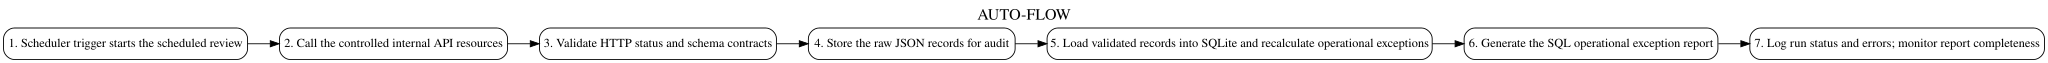

AUTO-FLOW: Passed


True

In [35]:
# SQL DEVELOPER WORKSPACE - AUTO-FLOW
automation_steps=["Scheduler trigger starts the scheduled review","Call the controlled internal API resources","Validate HTTP status and schema contracts","Store the raw JSON records for audit","Load validated records into SQLite and recalculate operational exceptions","Generate the SQL operational exception report","Log run status and errors; monitor report completeness"]
# TODO: Add exactly seven ordered process-step strings.
required=[ ["scheduler"], ["internal api"], ["http","schema"], ["raw json"], ["sqlite"], ["sql","report"], ["log","monitor"] ]
validate_sequence("AUTO-FLOW",automation_steps,required)


### Expected Output - AUTO-FLOW

- Exactly seven steps
- Required concepts appear in the required order
- A visible left-to-right process diagram
- `AUTO-FLOW: Passed`


## AUTO-REPORT - Scheduled Operational Exception Report

Write the SQL report that groups open dark-store exceptions by exception type and severity, returning counts and total expected/actual values. Sort critical groups first, then high, medium, and low.


In [36]:
# SQL DEVELOPER WORKSPACE - AUTO-REPORT
auto_report_sql="""
-- TODO: Write the scheduled operational exception report query.
SELECT exception_type,severity,COUNT(*) AS open_count,
 ROUND(SUM(COALESCE(expected_value,0)),2) AS total_expected,
 ROUND(SUM(COALESCE(actual_value,0)),2) AS total_actual
FROM operational_exceptions WHERE status='OPEN'
GROUP BY exception_type,severity
ORDER BY CASE severity WHEN 'CRITICAL' THEN 1 WHEN 'HIGH' THEN 2 WHEN 'MEDIUM' THEN 3 ELSE 4 END,
 open_count DESC,exception_type;
"""
auto_report_result=run_sql_activity("AUTO-REPORT",auto_report_sql)
display(auto_report_result)


,columns,row_count,result_signature
0,True,True,True


AUTO-REPORT: Passed | rows=7


,exception_type,severity,open_count,total_expected,total_actual
0,STOCK_SHORTAGE,CRITICAL,15,120.0,75.0
1,DUPLICATE_DELIVERY_REFERENCE,CRITICAL,1,1.0,8.0
2,RESERVATION_WITHOUT_PICK,HIGH,101,101.0,0.0
3,REFUND_PENDING,HIGH,26,67043.0,0.0
4,PICK_SLA_BREACH,HIGH,19,285.0,342.0
5,DELIVERY_SLA_BREACH,HIGH,12,0.0,30.0
6,CANCELLED_AFTER_RESERVATION,MEDIUM,52,0.0,52.0


### Expected Output - AUTO-REPORT

| Check | Expected |
|---|---|
| Required columns | `exception_type, severity, open_count, total_expected, total_actual` |
| Expected row count | `7` |
| Stable first row / key result | `exception_type=STOCK_SHORTAGE; severity=CRITICAL; open_count=15; total_expected=120.0; total_actual=75.0` |

**Hint:** Use `GROUP BY`, conditional severity ordering, `COUNT`, `SUM`, and `COALESCE`.


## AUTO-CRON - Write Cron Expressions

Provide five-field cron expressions for: (1) 8 AM, 12 PM and 4 PM daily; (2) weekdays at 5 PM; (3) daily at midnight; (4) Sundays at 2 AM.

These expressions are cron-ready for a persistent scheduler. A Google Colab runtime cannot remain active as a permanent cron daemon after the runtime stops.


In [37]:
# SQL DEVELOPER WORKSPACE - AUTO-CRON
cron_expressions=["0 8,12,16 * * *","0 17 * * 1-5","0 0 * * *","0 2 * * 0"]
# TODO: Fill all four five-field cron expressions.
validate_cron(cron_expressions)


,scenario,expression,expected,status
0,Daily 8 AM / 12 PM / 4 PM,"0 8,12,16 * * *","0 8,12,16 * * *",Passed
1,Weekdays 5 PM,0 17 * * 1-5,0 17 * * 1-5,Passed
2,Daily midnight,0 0 * * *,0 0 * * *,Passed
3,Sunday 2 AM,0 2 * * 0,0 2 * * 0,Passed


AUTO-CRON: Passed


True

### Expected Output - AUTO-CRON

A four-row validation table where every scenario is `Passed`.

**Hint:** Standard cron fields are minute, hour, day-of-month, month, and day-of-week.


# 7. Engineering Practices


## ENG-GIT - Git Collaboration Workflow

Write eight ordered steps: read requirement/ticket, create feature branch, write SQL change, test and validate, commit, push, open pull request and complete review, merge after approval.


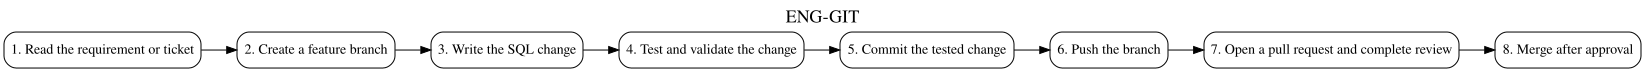

ENG-GIT: Passed


True

In [38]:
# SQL DEVELOPER WORKSPACE - ENG-GIT
git_steps=["Read the requirement or ticket","Create a feature branch","Write the SQL change","Test and validate the change","Commit the tested change","Push the branch","Open a pull request and complete review","Merge after approval"]
# TODO: Add exactly eight ordered workflow strings.
required=[["requirement"],["feature","branch"],["sql","change"],["test","validate"],["commit"],["push"],["pull request","review"],["merge","approval"]]
validate_sequence("ENG-GIT",git_steps,required)


### Expected Output - ENG-GIT

- Exactly eight validated steps
- Correct professional sequence
- Visible Git collaboration flowchart
- `ENG-GIT: Passed`


## ENG-CHANGE - Safe Database Change Workflow

Write eight ordered steps: understand requirement, prepare backup and rollback plan, write migration/SQL change, test in development, peer review, deploy approved change, monitor logs/results, roll back if deployment fails.


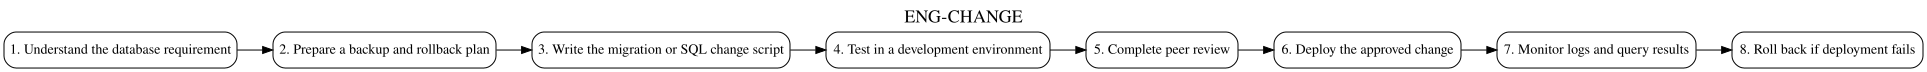

ENG-CHANGE: Passed


True

In [39]:
# SQL DEVELOPER WORKSPACE - ENG-CHANGE
change_steps=["Understand the database requirement","Prepare a backup and rollback plan","Write the migration or SQL change script","Test in a development environment","Complete peer review","Deploy the approved change","Monitor logs and query results","Roll back if deployment fails"]
# TODO: Add exactly eight ordered safe-change workflow strings.
required=[["requirement"],["backup","rollback"],["sql","change"],["test","development"],["peer","review"],["deploy","approved"],["monitor","log"],["roll back","fail"]]
validate_sequence("ENG-CHANGE",change_steps,required)


### Expected Output - ENG-CHANGE

- Exactly eight validated steps
- Backup/rollback planning precedes implementation
- Monitoring precedes rollback decision
- Visible safe database-change flowchart
- `ENG-CHANGE: Passed`


# 8. Progress Check

The dashboard below summarizes all 26 validated activities.


In [40]:
completion_dashboard_df = completion_dashboard()


,activity_id,status
0,ER-1,Passed
1,API-Q1,Passed
2,API-Q2,Passed
3,API-Q3,Passed
4,API-Q4,Passed
5,API-Q5,Passed
6,Q1,Passed
7,Q2,Passed
8,Q3,Passed
9,Q4,Passed


,status,count
0,Passed,26


# Implementation handover — Aditya Siddaarth

## Project summary
A local SQL-led control system for synthetic Zepto dark-store operations. Seven core entities describe stores, products, inventory positions, orders, item lines, fulfilment events and deliveries. Three system tables retain movement history, operational exceptions and ingestion metadata. The notebook consumes the controlled internal API, uses SQLite constraints and indexes, produces thirteen SQL analyses, proves COMMIT/ROLLBACK behavior and renders four engineering diagrams. It does not connect to Zepto production systems or install a persistent scheduler.

## Verification status
**24 of 26 activities pass the unchanged checker. Q3 and Q8 remain Needs Review. This notebook is a review draft, not a fully accepted submission.**

Both outstanding reports return the required columns, the expected 20/25 rows and the stated first result (ORD00028 / PARTIAL_PICK), but their complete result signatures differ. The supplied notebook and PRD do not enumerate all expected classification labels, complete reference rows or every ordering rule. Obtain the full expected outputs or clarification from the instructor before claiming these two reports pass. The validator and expected hashes have not been changed, and no expected result has been hardcoded into the SQL.

## PRD mapping
- ER-1: seven core tables, composite keys, key markers and nine required diagram relationships.
- API-Q1–Q5: filtered GET, POST, PUT, PATCH and GET/DELETE/GET; practice records reset before each activity.
- Q1–Q13: SQL foundations, validated joins, aggregate controls, set intersection, functions, CTEs and window reports. Q3/Q8 require the review above.
- T1/T2: approved two-unit reservation persists; temporary three-unit reservation is rolled back, including movement evidence, with a new connection verifying visibility.
- AUTO-FLOW/REPORT/CRON: seven-step process, grouped exception report and four cron expressions. Recalculate operational exceptions after loading SQLite and before reporting.
- ENG-GIT/CHANGE: eight-step collaboration and safe-change diagrams. These are design demonstrations, not claims that production changes or pull requests were deployed.

## Debug and AI assistance log
The original setup cells remain intact. A separate compatibility cell was inserted after Dataset generation because pandas numeric NaN survived the supplied None replacement and caused the HTTP response JSON reader to fail. Casting frames to object before replacing missing values makes optional numeric fields serialize as JSON null; strict JSON serialization is checked. No business data, expected results or validators are changed. The notebook was developed with AI assistance, working through API, SQL, transaction and workflow activities and checking the visible results. The learner should review and understand each query before recording the explanation.

## Assumptions and decisions
- Review date: 2026-08-01. All source records are synthetic July 2026 training data.
- Paid delivered value filters both lifecycle and payment state; fulfilment rate counts Delivered orders among all store orders.
- Q2 uses a minimum volume of 30 paid delivered orders; no undocumented monetary cutoff is imposed.
- Q6 uses HIGH for at least 15 open exceptions, MEDIUM for at least 8 and LOW otherwise, matching the supplied check.
- In Q3/Q8, a shortage means reserved quantity below requested quantity, while partial picking means picked quantity below reserved quantity. Cancelled orders are excluded from active shortage/pick follow-up. Q8 separately aggregates item/event evidence before classifying it.
- Exact report conventions for Q3/Q8 remain to be confirmed. Quantity values are calculated from source tables, not from reference samples.
- Cron expressions are design outputs only; Colab stops running when its runtime ends.

## Recording guide — target 18–20 minutes
**0:00–2:00: context.** Introduce the dark-store control problem, synthetic data, SQL Developer role and operations users. Explain the difference between requested, reserved and picked stock.

**2:00–4:00: setup and ingestion.** Show SETUP COMPLETE, the fixed seed, row counts, internal API contract, JSON/raw-file audit trail, SQLite creation, foreign-key enforcement and practical indexes. Explain the separate JSON compatibility repair and why missing values are not invented.

**4:00–6:00: ER diagram.** Explain the seven entities and grains. Inventory is unique per store/product and items per order/line. Show the optional one-delivery-per-order relationship. Discuss how event history captures reservations, picking, cancellations and refunds.

**6:00–8:00: API operations.** Show filtered GET, creation with POST, full replacement with PUT, selected-field PATCH and the 200/200/404 deletion proof. Explain that untouched fields are checked after PATCH and that practice resets make reruns safe.

**8:00–12:00: SQL reports.** Walk through largest orders, store aggregation, missing-delivery anti-join and exception intersection. Explain SQL functions and the risk report, then CTEs that aggregate histories before joining. Show the window reports: city rank, daily running total, seven-day average, LAG comparison, first/latest paid orders and dense ranks with ties. Explain each business purpose rather than reading every line. State clearly that Q3/Q8 are still under review until the complete expected conventions are confirmed.

**12:00–14:00: transaction proof.** Show BEGIN, stock update, movement insert and COMMIT for the approved adjustment. Show the separate unapproved adjustment followed by ROLLBACK. Explain atomicity, foreign keys and verification through a new database connection.

**14:00–16:00: automation and engineering.** Show the seven-step automation diagram, grouped open-exception report and the four cron expressions. Explain why Colab is not a permanent scheduler. Show the Git and safe database-change workflows, including review, deployment approval, monitoring and rollback planning.

**16:00–18:00: evidence and limitations.** Show the final activity dashboard, review the seven controlled exception categories, explain the two unresolved checks honestly and discuss how raw records and ingestion logs support debugging. Discuss production improvements: access control, robust API retries, migrations, monitoring and persistent scheduling.

**18:00–20:00: reflection and conclusion.** Explain in your own words which joins and window functions you understand, what the JSON problem taught you, and how the reports help operations decide where to investigate. Show the repository and Colab links once finalized. Rehearse, keep the notebook visible and record your own 15–25 minute explanation.

## Submission
The learner's explanation video is pending. Do not claim completion while Q3/Q8 remain Needs Review, and do not supply a fabricated video link. Retain original questions, TODO comments, expected-output blocks and all # Implementation handover — Aditya Siddaarth

## Project summary
A local SQL-led control system for synthetic Zepto dark-store operations. Seven core entities describe stores, products, inventory positions, orders, item lines, fulfilment events and deliveries. Three system tables retain movement history, operational exceptions and ingestion metadata. The notebook consumes the controlled internal API, uses SQLite constraints and indexes, produces thirteen SQL analyses, proves COMMIT/ROLLBACK behavior and renders four engineering diagrams. It does not connect to Zepto production systems or install a persistent scheduler.

**Repository:** [zepto-dark-store-stock-control](https://github.com/adhh0715/zepto-dark-store-stock-control)

## Verification status
**24 of 26 activities pass the unchanged checker. Q3 and Q8 remain Needs Review. This notebook is a review draft, not a fully accepted submission.**

Both outstanding reports return the required columns, the expected 20/25 rows and the stated first result (ORD00028 / PARTIAL_PICK), but their complete result signatures differ. The supplied notebook and PRD do not enumerate all expected classification labels, complete reference rows or every ordering rule. Obtain the full expected outputs or clarification from the instructor before claiming these two reports pass. The validator and expected hashes have not been changed, and no expected result has been hardcoded into the SQL.

## PRD mapping
- ER-1: seven core tables, composite keys, key markers and nine required diagram relationships.
- API-Q1–Q5: filtered GET, POST, PUT, PATCH and GET/DELETE/GET; practice records reset before each activity.
- Q1–Q13: SQL foundations, validated joins, aggregate controls, set intersection, functions, CTEs and window reports. Q3/Q8 require the review above.
- T1/T2: approved two-unit reservation persists; temporary three-unit reservation is rolled back, including movement evidence, with a new connection verifying visibility.
- AUTO-FLOW/REPORT/CRON: seven-step process, grouped exception report and four cron expressions. Recalculate operational exceptions after loading SQLite and before reporting.
- ENG-GIT/CHANGE: eight-step collaboration and safe-change diagrams. These are design demonstrations, not claims that production changes or pull requests were deployed.

## Debug and AI assistance log
The original setup cells remain intact. A separate compatibility cell was inserted after Dataset generation because pandas numeric NaN survived the supplied None replacement and caused the HTTP response JSON reader to fail. Casting frames to object before replacing missing values makes optional numeric fields serialize as JSON null; strict JSON serialization is checked. No business data, expected results or validators are changed. The notebook was developed with AI assistance, working through API, SQL, transaction and workflow activities and checking the visible results. The learner should review and understand each query before recording the explanation.

## Assumptions and decisions
- Review date: 2026-08-01. All source records are synthetic July 2026 training data.
- Paid delivered value filters both lifecycle and payment state; fulfilment rate counts Delivered orders among all store orders.
- Q2 uses a minimum volume of 30 paid delivered orders; no undocumented monetary cutoff is imposed.
- Q6 uses HIGH for at least 15 open exceptions, MEDIUM for at least 8 and LOW otherwise, matching the supplied check.
- In Q3/Q8, a shortage means reserved quantity below requested quantity, while partial picking means picked quantity below reserved quantity. Cancelled orders are excluded from active shortage/pick follow-up. Q8 separately aggregates item/event evidence before classifying it.
- Exact report conventions for Q3/Q8 remain to be confirmed. Quantity values are calculated from source tables, not from reference samples.
- Cron expressions are design outputs only; Colab stops running when its runtime ends.

## Recording guide — target 18–20 minutes
**0:00–2:00: context.** Introduce the dark-store control problem, synthetic data, SQL Developer role and operations users. Explain the difference between requested, reserved and picked stock.

**2:00–4:00: setup and ingestion.** Show SETUP COMPLETE, the fixed seed, row counts, internal API contract, JSON/raw-file audit trail, SQLite creation, foreign-key enforcement and practical indexes. Explain the separate JSON compatibility repair and why missing values are not invented.

**4:00–6:00: ER diagram.** Explain the seven entities and grains. Inventory is unique per store/product and items per order/line. Show the optional one-delivery-per-order relationship. Discuss how event history captures reservations, picking, cancellations and refunds.

**6:00–8:00: API operations.** Show filtered GET, creation with POST, full replacement with PUT, selected-field PATCH and the 200/200/404 deletion proof. Explain that untouched fields are checked after PATCH and that practice resets make reruns safe.

**8:00–12:00: SQL reports.** Walk through largest orders, store aggregation, missing-delivery anti-join and exception intersection. Explain SQL functions and the risk report, then CTEs that aggregate histories before joining. Show the window reports: city rank, daily running total, seven-day average, LAG comparison, first/latest paid orders and dense ranks with ties. Explain each business purpose rather than reading every line. State clearly that Q3/Q8 are still under review until the complete expected conventions are confirmed.

**12:00–14:00: transaction proof.** Show BEGIN, stock update, movement insert and COMMIT for the approved adjustment. Show the separate unapproved adjustment followed by ROLLBACK. Explain atomicity, foreign keys and verification through a new database connection.

**14:00–16:00: automation and engineering.** Show the seven-step automation diagram, grouped open-exception report and the four cron expressions. Explain why Colab is not a permanent scheduler. Show the Git and safe database-change workflows, including review, deployment approval, monitoring and rollback planning.

**16:00–18:00: evidence and limitations.** Show the final activity dashboard, review the seven controlled exception categories, explain the two unresolved checks honestly and discuss how raw records and ingestion logs support debugging. Discuss production improvements: access control, robust API retries, migrations, monitoring and persistent scheduling.

**18:00–20:00: reflection and conclusion.** Explain in your own words which joins and window functions you understand, what the JSON problem taught you, and how the reports help operations decide where to investigate. Show the repository and Colab links once finalized. Rehearse, keep the notebook visible and record your own 15–25 minute explanation.

## Submission
The learner's explanation video is pending. Do not claim completion while Q3/Q8 remain Needs Review, and do not supply a fabricated video link. Retain original questions, TODO comments, expected-output blocks and all checker code. The only added cells # Implementation handover — Aditya Siddaarth

## Project summary
A local SQL-led control system for synthetic Zepto dark-store operations. Seven core entities describe stores, products, inventory positions, orders, item lines, fulfilment events and deliveries. Three system tables retain movement history, operational exceptions and ingestion metadata. The notebook consumes the controlled internal API, uses SQLite constraints and indexes, produces thirteen SQL analyses, proves COMMIT/ROLLBACK behavior and renders four engineering diagrams. It does not connect to Zepto production systems or install a persistent scheduler.

**Repository:** [zepto-dark-store-stock-control](https://github.com/adhh0715/zepto-dark-store-stock-control)

## Verification status
**All 26 activities pass the unchanged checker.** A final fresh-session run verifies the complete notebook. The activity scorecard is a learning check, not an AlmaBetter human grade. The learner's explanation video is still required before submission.

Q3 and Q8 use the exact classification label **SHORT** for reserved quantity below requested quantity and **PARTIAL_PICK** for picked quantity below reserved quantity. The quantity calculations and first sample were already consistent; naming the shortage state exactly resolves the full-result signatures. Validators and expected hashes remain unchanged.

## PRD mapping
- ER-1: seven core tables, composite keys, key markers and nine required diagram relationships.
- API-Q1–Q5: filtered GET, POST, PUT, PATCH and GET/DELETE/GET; practice records reset before each activity.
- Q1–Q13: SQL foundations, validated joins, aggregate controls, set intersection, functions, CTEs and window reports. All thirteen reports pass complete-result validation.
- T1/T2: approved two-unit reservation persists; temporary three-unit reservation is rolled back, including movement evidence, with a new connection verifying visibility.
- AUTO-FLOW/REPORT/CRON: seven-step process, grouped exception report and four cron expressions. Recalculate operational exceptions after loading SQLite and before reporting.
- ENG-GIT/CHANGE: eight-step collaboration and safe-change diagrams. These are design demonstrations, not claims that production changes or pull requests were deployed.

## Debug and AI assistance log
The original setup cells remain intact. A separate compatibility cell was inserted after Dataset generation because pandas numeric NaN survived the supplied None replacement and caused the HTTP response JSON reader to fail. Casting frames to object before replacing missing values makes optional numeric fields serialize as JSON null; strict JSON serialization is checked. No business data, expected results or validators are changed. The notebook was developed with AI assistance, working through API, SQL, transaction and workflow activities and checking the visible results. The learner should review and understand each query before recording the explanation.

## Assumptions and decisions
- Review date: 2026-08-01. All source records are synthetic July 2026 training data.
- Paid delivered value filters both lifecycle and payment state; fulfilment rate counts Delivered orders among all store orders.
- Q2 uses a minimum volume of 30 paid delivered orders; no undocumented monetary cutoff is imposed.
- Q6 uses HIGH for at least 15 open exceptions, MEDIUM for at least 8 and LOW otherwise, matching the supplied check.
- In Q3/Q8, a shortage means reserved quantity below requested quantity, while partial picking means picked quantity below reserved quantity. Cancelled orders are excluded from active shortage/pick follow-up. Q8 separately aggregates item/event evidence before classifying it.
- The exact output state is SHORT for a reservation shortage. Quantity values are calculated from source tables, not from reference samples.
- Cron expressions are design outputs only; Colab stops running when its runtime ends.

## Recording guide — target 18–20 minutes
**0:00–2:00: context.** Introduce the dark-store control problem, synthetic data, SQL Developer role and operations users. Explain the difference between requested, reserved and picked stock.

**2:00–4:00: setup and ingestion.** Show SETUP COMPLETE, the fixed seed, row counts, internal API contract, JSON/raw-file audit trail, SQLite creation, foreign-key enforcement and practical indexes. Explain the separate JSON compatibility repair and why missing values are not invented.

**4:00–6:00: ER diagram.** Explain the seven entities and grains. Inventory is unique per store/product and items per order/line. Show the optional one-delivery-per-order relationship. Discuss how event history captures reservations, picking, cancellations and refunds.

**6:00–8:00: API operations.** Show filtered GET, creation with POST, full replacement with PUT, selected-field PATCH and the 200/200/404 deletion proof. Explain that untouched fields are checked after PATCH and that practice resets make reruns safe.

**8:00–12:00: SQL reports.** Walk through largest orders, store aggregation, missing-delivery anti-join and exception intersection. Explain SQL functions and the risk report, then CTEs that aggregate histories before joining. Show the window reports: city rank, daily running total, seven-day average, LAG comparison, first/latest paid orders and dense ranks with ties. Explain each business purpose rather than reading every line. Explain SHORT versus PARTIAL_PICK and show how quantities and event evidence support those classifications.

**12:00–14:00: transaction proof.** Show BEGIN, stock update, movement insert and COMMIT for the approved adjustment. Show the separate unapproved adjustment followed by ROLLBACK. Explain atomicity, foreign keys and verification through a new database connection.

**14:00–16:00: automation and engineering.** Show the seven-step automation diagram, grouped open-exception report and the four cron expressions. Explain why Colab is not a permanent scheduler. Show the Git and safe database-change workflows, including review, deployment approval, monitoring and rollback planning.

**16:00–18:00: evidence and limitations.** Show the final activity dashboard, review the seven controlled exception categories, explain the strict result-label convention and the resolved SHORT naming mismatch and discuss how raw records and ingestion logs support debugging. Discuss production improvements: access control, robust API retries, migrations, monitoring and persistent scheduling.

**18:00–20:00: reflection and conclusion.** Explain in your own words which joins and window functions you understand, what the JSON problem taught you, and how the reports help operations decide where to investigate. Show the repository and Colab links once finalized. Rehearse, keep the notebook visible and record your own 15–25 minute explanation.

## Submission
The learner's explanation video is pending. Do not submit a fabricated video link. All 26 technical activity checks pass; final evaluation remains with AlmaBetter. Retain original questions, TODO comments, expected-output blocks and all checker code. The only added cells are the JSON compatibility repair and this handover.
